# Домашняя работа: анализ scRNA-seq миндалин человека

**Датасет:** Human tonsil complete integrated cell set scRNA (проект «Single-cell analysis of human B cell maturation predicts how antibody class switching shapes selection dynamics»)

**Ткань / организм:** небные миндалины (tonsil), *Homo sapiens*; несортированные иммунные клетки детей

**Размер:** 32 607 клеток × 19 517 генов, 7 доноров. В анализе: случайная подвыборка 12 000 клеток (`seed=0`), все доноры вместе

**Источник данных:** CELLxGENE, https://cellxgene.cziscience.com/datasets (набор «Human tonsil complete integrated cell set scRNA»); сырые данные в ArrayExpress: E-MTAB-9005 (scRNA-seq), E-MTAB-9003 (scVDJ-seq), E-MTAB-8999 (bulk-репертуар антител)

**Статья:** King H. W. et al. (2021). Single-cell analysis of human B cell maturation predicts how antibody class switching shapes selection dynamics. *Science Immunology*.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.sparse import issparse, csr_matrix
import warnings
warnings.filterwarnings("ignore", message="Variable names are not unique")

sc.settings.verbosity = 1
sc.set_figure_params(figsize=(5, 4), dpi=90, frameon=False)
SEED = 0
np.random.seed(SEED)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

## Задание 1. Данные и контроль качества (QC)

### 1.1. Загрузка

Файлы CELLxGENE хранят в `.X` обычно уже нормализованные значения, а сырые счётчики лежат в `.raw.X`. Поэтому ячейка ниже сама ищет счётчики (`.raw` → `layers['counts']` → `.X`) и **проверяет, что это целые числа**. Гены переименовываются в символы (`feature_name`) вместо Ensembl ID.

In [4]:
H5AD_PATH = DATA_DIR / "lymphoid.h5ad"
MAX_CELLS = 12000          # если клеток больше, случайная подвыборка (ради скорости)

ad = sc.read_h5ad(H5AD_PATH)
print(ad)

#поиск сырых счётчиков
if ad.raw is not None:
    X, var, src = ad.raw.X, ad.raw.var, ".raw.X"
elif "counts" in ad.layers:
    X, var, src = ad.layers["counts"], ad.var, "layers['counts']"
else:
    X, var, src = ad.X, ad.var, ".X"

sample = X[:2000].data if issparse(X) else np.asarray(X[:2000]).ravel()
if not np.allclose(sample, np.round(sample)):
    raise ValueError(f"В {src} не целые числа, это не сырые счётчики. Выберите другой датасет или файл.")
print("Сырые счётчики найдены в", src)

#имена генов
names = var["feature_name"].astype(str) if "feature_name" in var.columns else pd.Series(var.index, index=var.index)
hw = sc.AnnData(X=csr_matrix(X).astype(np.float32), obs=ad.obs.copy(), var=pd.DataFrame(index=names.values))
hw.var_names_make_unique()
del ad

#подвыборка при необходимости
if hw.n_obs > MAX_CELLS:
    keep_idx = np.sort(np.random.choice(hw.n_obs, MAX_CELLS, replace=False))
    hw = hw[keep_idx].copy()
    print(f"Случайная подвыборка до {MAX_CELLS} клеток")

print(f"Клеток: {hw.n_obs}, генов: {hw.n_vars}")
print("Доля нулей:", f"{1 - hw.X.nnz / (hw.n_obs * hw.n_vars):.1%}")

AnnData object with n_obs × n_vars = 32607 × 19517
    obs: 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'percent.ribo', 'donor_id', 'Sample', 'assay_ontology_term_id', 'Status', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'ScrubletPrediction', 'DoubletFinderPrediction', 'ChainStatus', 'author_cell_type', 'barcode', 'Lineage', 'SEQUENCE_ID', 'IGH_FUNCTIONAL', 'IGH_IN_FRAME', 'IGH_STOP', 'IGH_V_CALL_GENOTYPED', 'IGH_D_CALL', 'IGH_J_CALL', 'IGH_JUNCTION_LENGTH', 'ISOTYPE', 'CLONE_ID', 'IGK_C_Gene', 'IGK_VDJ_Gene', 'IGK_FullLength', 'IGK_Productive', 'IGL_C_Gene', 'IGL_VDJ_Gene', 'IGL_FullLength', 'IGL_Productive', 'IGH_UMIS', 'IGH_MU_FREQ', 'IGK_UMIS', 'IGL_UMIS', 'is_primary_data', 'self_reported_ethnicity_ontology_term_id', 'suspension_type', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'obstructive_sleep_apnea', 'recurrent_tonsillitis', 'cell_type_ontology_term_id', 'tissue_type', 'cell_type', 'assay', 'dis

In [5]:
# Что известно о происхождении клеток (колонки CELLxGENE, если есть)
for col in ["tissue", "tissue_general", "assay", "disease", "donor_id", "sex", "development_stage",
            "suspension_type", "dataset_id", "cell_type"]:
    if col in hw.obs.columns:
        vc = hw.obs[col].value_counts()
        print(f"{col}: {len(vc)} значений; топ: {dict(vc.head(5))}")

tissue: 1 значений; топ: {'tonsil': np.int64(12000)}
assay: 2 значений; топ: {"10x 5' v1": np.int64(11208), "10x 3' v2": np.int64(792)}
disease: 1 значений; топ: {'normal': np.int64(12000)}
donor_id: 7 значений; топ: {'BCP5': np.int64(5616), 'BCP6': np.int64(1694), 'BCP9': np.int64(1593), 'BCP8': np.int64(1138), 'BCP3': np.int64(798)}
sex: 2 значений; топ: {'male': np.int64(7915), 'female': np.int64(4085)}
development_stage: 4 значений; топ: {'3-year-old stage': np.int64(6754), '6-year-old stage': np.int64(1959), '5-year-old stage': np.int64(1694), '9-year-old stage': np.int64(1593)}
suspension_type: 1 значений; топ: {'cell': np.int64(12000)}
cell_type: 22 значений; топ: {'tonsil germinal center B cell': np.int64(3831), 'naive B cell': np.int64(1949), 'memory B cell': np.int64(1205), 'T follicular helper cell': np.int64(1189), 'centroblast': np.int64(664)}


### 1.2. Описание данных

- **Ткань и клетки.** Все иммунные клетки небных миндалин детей (3-9 лет, миндалины удалены при апноэ сна или рецидивирующем тонзиллите). Это вторичный лимфоидный орган: в нём B-клетки, T-клетки, плазматические и миелоидные клетки.
- **Вопрос авторов.** Как созревают B-клетки: от наивных через герминальный центр к клеткам памяти и плазматическим клеткам, и как смена класса антител влияет на отбор клонов.
- **Размер.** В файле 32 607 клеток и 19 517 генов, 92 % матрицы это нули. Для скорости взята случайная подвыборка 12 000 клеток.
- **Доноры и технологии.** В подвыборке 7 доноров, больше всего клеток у BCP5 (5 616). 11 208 клеток измерены на 5' v1 и 792 (донор BCP2) на 3' v2.

In [6]:
# Какие доноры и библиотеки есть в данных (справка, все клетки оставляем)
cands = [c for c in hw.obs.columns if any(k in c.lower() for k in ["donor", "sample", "batch", "library"])]
for c in cands:
    print(c, "->", hw.obs[c].nunique(), "значений:", dict(hw.obs[c].value_counts().head(6)))

donor_id -> 7 значений: {'BCP5': np.int64(5616), 'BCP6': np.int64(1694), 'BCP9': np.int64(1593), 'BCP8': np.int64(1138), 'BCP3': np.int64(798), 'BCP2': np.int64(792)}
Sample -> 7 значений: {'BCP5_Total': np.int64(5616), 'BCP6_Total': np.int64(1694), 'BCP9_Total': np.int64(1593), 'BCP8_Total': np.int64(1138), 'BCP3_Total': np.int64(798), 'BCP2_Total': np.int64(792)}


### 1.3. Метрики QC

`total_counts` (число молекул UMI), `n_genes_by_counts` (число разных генов), `pct_counts_mt` (доля митохондриальных генов `MT-`).

Митохондриальных генов: 0


,total_counts,n_genes_by_counts,pct_counts_mt
count,12000.00,12000.00,12000.0
mean,4922.34,1564.46,0.0
std,5070.03,922.69,0.0
min,878.00,497.00,0.0
1%,1029.99,534.00,0.0
5%,1197.00,615.00,0.0
50%,3449.00,1323.00,0.0
95%,13938.20,3497.10,0.0
99%,26380.48,4937.05,0.0
max,56948.00,6587.00,0.0


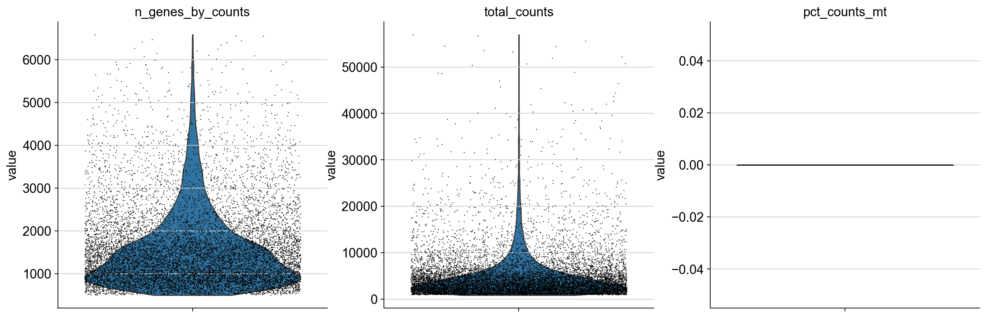

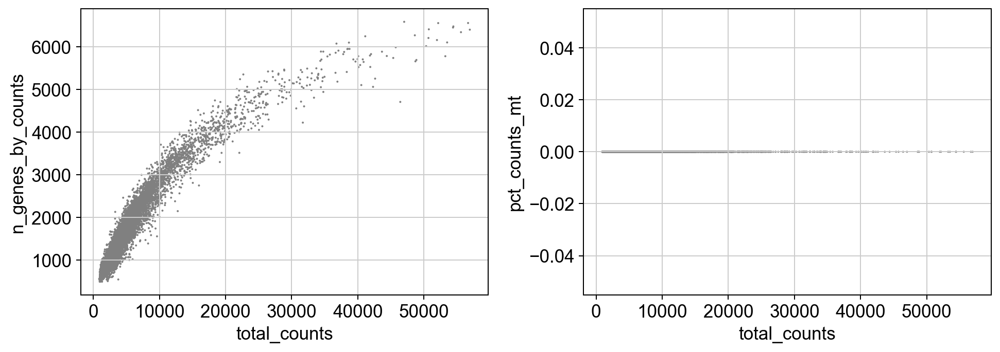

In [7]:
hw.var["mt"] = hw.var_names.str.startswith("MT-")
print("Митохондриальных генов:", int(hw.var["mt"].sum()))
sc.pp.calculate_qc_metrics(hw, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
display(hw.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe(
    percentiles=[.01, .05, .5, .95, .99]).round(2))

sc.pl.violin(hw, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], jitter=0.4, multi_panel=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sc.pl.scatter(hw, x="total_counts", y="n_genes_by_counts", ax=axes[0], show=False)
sc.pl.scatter(hw, x="total_counts", y="pct_counts_mt", ax=axes[1], show=False)
plt.tight_layout(); plt.show()

In [8]:
# Дополнительно: в obs есть собственные метрики авторов (в матрице MT-генов нет, см. ниже)
for col in ["percent.mito", "percent.ribo"]:
    if col in hw.obs.columns:
        print(col); display(hw.obs[col].astype(float).describe(percentiles=[.5, .95, .99]).round(3).to_frame().T)
for col in ["ScrubletPrediction", "DoubletFinderPrediction"]:
    if col in hw.obs.columns:
        print(col, dict(hw.obs[col].astype(str).value_counts()))

percent.mito


,count,mean,std,min,50%,95%,99%,max
percent.mito,12000.0,0.046,0.029,0.0,0.043,0.096,0.135,0.298


percent.ribo


,count,mean,std,min,50%,95%,99%,max
percent.ribo,12000.0,0.312,0.091,0.006,0.311,0.465,0.547,0.751


ScrubletPrediction {'False': np.int64(11764), 'True': np.int64(236)}
DoubletFinderPrediction {'Singlet': np.int64(11032), 'Doublet_hi': np.int64(900), 'Doublet_lo': np.int64(68)}


### 1.4. Пороги фильтрации

Выбранные пороги:
- минимум 200 генов на клетку: убирает пустые капли и обломки;
- максимум 4 937 генов (99-й перцентиль): убирает вероятные дублеты, ведь две клетки в одной капле дают почти вдвое больше генов;
- максимум 10 % митохондриальных генов: убирает умирающие клетки, у которых мРНК цитоплазмы вытекла, а митохондриальная осталась;
- гены, найденные меньше чем в 3 клетках, убираем: по ним нечего сравнивать.

Что получилось:
- В данных нет митохондриальных генов (`MT-`): авторы убрали их до публикации. Поэтому `pct_counts_mt` везде равен 0, и этот порог ничего не удалил. Собственная колонка авторов `percent.mito` выведена ячейкой выше только для справки, в фильтрации она не использована.
- Нижний порог по генам тоже ничего не удалил: минимум в данных 497 генов, слабые клетки авторы уже убрали.
- Сработал только верхний порог: удалено 120 клеток (1 %). Осталось 11 880 клеток и 17 335 генов (убрано 2 182 редких гена).
- Авторы датасета сами отметили дублеты в `obs` (Scrublet 236 клеток, DoubletFinder 968). Мы их не удаляли и отбирали клетки только по числу генов, как требует задание.
- Перцентиль взят вместо фиксированного числа, потому что он подстраивается под глубину секвенирования конкретного набора. На графике `total_counts` против `n_genes_by_counts` виден длинный правый хвост: это одиночные клетки, далеко ушедшие от основной массы.

In [9]:
MIN_GENES = 200
MAX_GENES = int(np.quantile(hw.obs["n_genes_by_counts"], 0.99))
MAX_MT = 10.0
obs = hw.obs
n0, g0 = hw.n_obs, hw.n_vars

display(pd.Series({
    f"n_genes < {MIN_GENES}": int((obs["n_genes_by_counts"] < MIN_GENES).sum()),
    f"n_genes > {MAX_GENES} (99 перц.)": int((obs["n_genes_by_counts"] > MAX_GENES).sum()),
    f"pct_mt > {MAX_MT}%": int((obs["pct_counts_mt"] > MAX_MT).sum()),
}, name="клеток (критерии пересекаются)").to_frame())

keep = ((obs["n_genes_by_counts"] >= MIN_GENES) & (obs["n_genes_by_counts"] <= MAX_GENES)
        & (obs["pct_counts_mt"] <= MAX_MT))
hw = hw[keep].copy()
sc.pp.filter_genes(hw, min_cells=3)
print(f"Клетки: {n0} -> {hw.n_obs} (удалено {n0 - hw.n_obs}, {(n0 - hw.n_obs) / n0:.1%})")
print(f"Гены:   {g0} -> {hw.n_vars} (удалено {g0 - hw.n_vars})")

,клеток (критерии пересекаются)
n_genes < 200,0
n_genes > 4937 (99 перц.),120
pct_mt > 10.0%,0


Клетки: 12000 -> 11880 (удалено 120, 1.0%)
Гены:   19517 -> 17335 (удалено 2182)


## Задание 2. Нормализация и высоковариабельные гены (HVG)

Сохраняем сырые counts в `layers['counts']` (для `seurat_v3`), затем нормализуем на 10 000 UMI и берём `log1p`.

Выбрано HVG: 2000 из 17335


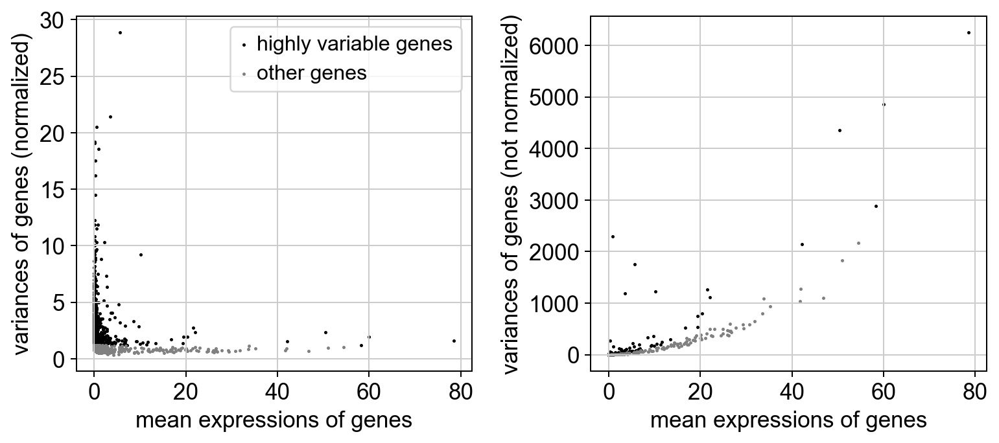

,highly_variable_rank,means,variances_norm,функция (из словаря)
JCHAIN,0.0,5.633,28.865,"J-цепь, плазматические клетки"
IGHM,1.0,3.554,21.425,тяжёлая цепь IgM
CCL4,2.0,0.532,20.535,заполнить вручную (GeneCards/UniProt)
CST3,3.0,0.176,19.170,заполнить вручную (GeneCards/UniProt)
GNLY,4.0,0.127,19.099,заполнить вручную (GeneCards/UniProt)
IGHD,5.0,1.015,18.559,"тяжёлая цепь IgD, наивные B"
LYZ,6.0,0.202,17.549,"лизоцим, миелоидные клетки"
CCL3,7.0,0.228,16.209,заполнить вручную (GeneCards/UniProt)
CXCL13,8.0,0.184,14.523,"хемокин, фолликулярные хелперные T / FDC"
CCL4L2,9.0,0.100,12.265,заполнить вручную (GeneCards/UniProt)


In [10]:
hw.layers["counts"] = hw.X.copy()
sc.pp.highly_variable_genes(hw, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pp.normalize_total(hw, target_sum=1e4)
sc.pp.log1p(hw)

print("Выбрано HVG:", int(hw.var["highly_variable"].sum()), "из", hw.n_vars)
sc.pl.highly_variable_genes(hw)

top10 = (hw.var.loc[hw.var["highly_variable"]].sort_values("highly_variable_rank").head(10)
         [["highly_variable_rank", "means", "variances_norm"]].round(3))
GENE_FUNCTION = {
    "CD74": "инвариантная цепь MHC II, презентация антигена",
    "HLA-DRA": "α-цепь MHC II", "HLA-DRB1": "β-цепь MHC II", "HLA-DPB1": "β-цепь MHC II (DP)",
    "HLA-DPA1": "α-цепь MHC II (DP)", "HLA-DQA1": "α-цепь MHC II (DQ)",
    "MS4A1": "CD20, маркер B-клеток", "CD79A": "компонент B-клеточного рецептора",
    "CD79B": "компонент B-клеточного рецептора", "IGKC": "константная область лёгкой цепи каппа",
    "IGLC2": "константная область лёгкой цепи лямбда", "IGHM": "тяжёлая цепь IgM",
    "IGHD": "тяжёлая цепь IgD, наивные B", "IGHG1": "тяжёлая цепь IgG1",
    "IGHA1": "тяжёлая цепь IgA1", "JCHAIN": "J-цепь, плазматические клетки",
    "MZB1": "шаперон плазматических клеток", "XBP1": "транскрипционный фактор UPR, плазматические клетки",
    "TCL1A": "наивные B-клетки", "CCL5": "хемокин эффекторных T и NK",
    "IL7R": "рецептор IL-7, T-клетки", "CD3D": "компонент TCR-комплекса",
    "CCR7": "хоминг в лимфоидные ткани, наивные и центральные памяти T",
    "CXCL13": "хемокин, фолликулярные хелперные T / FDC", "CXCR5": "рецептор CXCL13",
    "PDCD1": "PD-1, Tfh и истощённые T", "TNFRSF13B": "TACI, B-клетки памяти / плазматические",
    "LYZ": "лизоцим, миелоидные клетки", "S100A8": "кальгранулин, миелоидные",
    "S100A9": "кальгранулин, миелоидные", "MKI67": "маркер пролиферации",
    "TOP2A": "топоизомераза 2A, делящиеся клетки", "STMN1": "стабилизация микротрубочек, делящиеся клетки",
    "HBB": "бета-глобин (примесь эритроцитов)", "FDCSP": "секретируемый белок фолликулярных дендритных клеток",
}
top10["функция (из словаря)"] = [GENE_FUNCTION.get(g, "заполнить вручную (GeneCards/UniProt)") for g in top10.index]
display(top10)

**Функции 10 самых вариабельных генов** (по GeneCards и UniProt):

- `JCHAIN`: J-цепь, соединяет мономеры IgA и IgM в полимеры. Плазматические клетки.
- `IGHM`: тяжёлая цепь антитела IgM. Наивные B и плазматические клетки.
- `CCL4` и его копия `CCL4L2`: хемокин, привлекает T-клетки и моноциты. Активированные CD8 T, NK, макрофаги.
- `CST3`: цистатин C, ингибитор протеаз. Моноциты и дендритные клетки.
- `GNLY`: гранулизин, разрушает мембраны клеток-мишеней. Цитотоксические CD8 T и NK.
- `IGHD`: тяжёлая цепь антитела IgD. Наивные B.
- `LYZ`: лизоцим, расщепляет клеточную стенку бактерий. Моноциты и макрофаги.
- `CCL3`: хемокин MIP-1α. Активированные миелоидные клетки и T.
- `CXCL13`: хемокин, зовёт CXCR5+ B- и T-клетки в фолликул. Tfh и фолликулярные дендритные клетки.

Среди них три гена антител (`JCHAIN`, `IGHM`, `IGHD`) и четыре хемокина. Для лимфоидной ткани это ожидаемо: эти гены сильно различаются между B-, T-, плазматическими и миелоидными клетками.

**Зачем нужны HVG и почему не обязательно брать все гены для PCA и кластеризации.** 

1. Большинство из примерно 20 000 генов выражены одинаково во всех клетках («домашние» гены) или просто шумят. Типы клеток различают гены с вариабельностью выше ожидаемой, то есть HVG.
2. Тысячи шумных генов размывают расстояния между клетками, и PCA тратит компоненты на технический разброс.
3. PCA и поиск соседей на 2 000 признаках считаются заметно быстрее, чем на 20 000.
4. Гены не удаляются, а только помечаются в `var['highly_variable']`. Маркеры, не попавшие в HVG, всё равно видны на dotplot и в тесте на маркеры.

## Задание 3. PCA и кластеризация

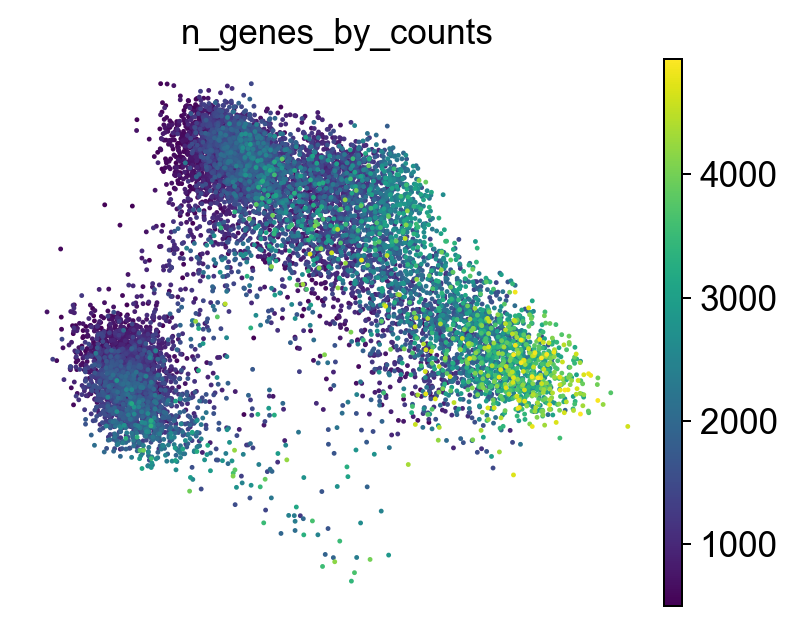

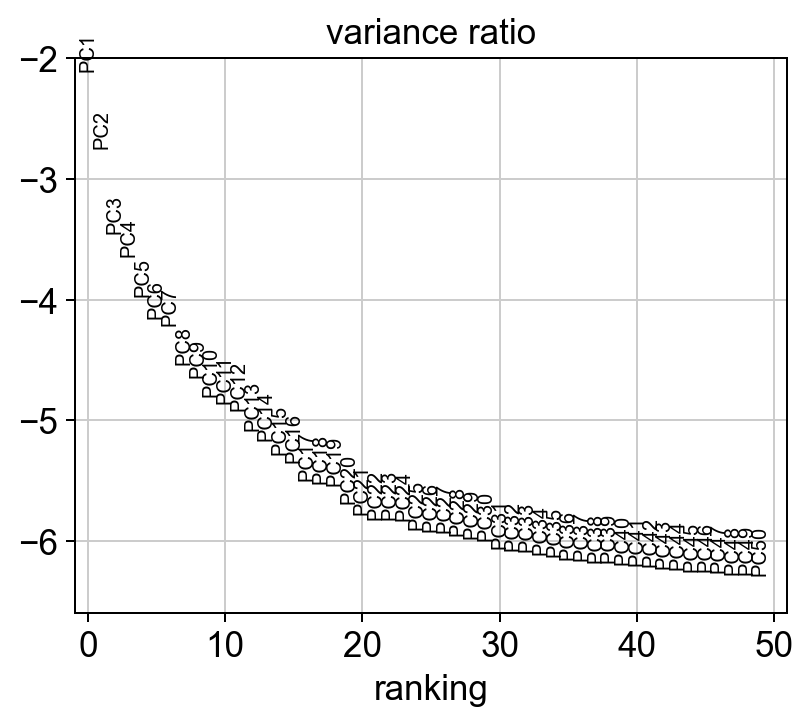

In [11]:
sc.tl.pca(hw, n_comps=50, mask_var="highly_variable", random_state=SEED)
sc.pl.pca(hw, color="n_genes_by_counts", components=["1,2"], size=15)
sc.pl.pca_variance_ratio(hw, n_pcs=50, log=True)

Мы видим на графике, что у первых компонент вариация заметно больше остальных, дальше кривая плавно спадает, перегиб примерно между 10-й и 20-й компонентами. Перед PCA мы не масштабировали гены (`sc.pp.scale`), данные уже log-нормализованы; кластеры получились биологически осмысленными, поэтому оставили так. Берём 30 первых с запасом: лишние слабые компоненты почти не мешают, а потерять реальную структуру было бы хуже.

/opt/anaconda3/envs/sc_hw39/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/h6/qvzvscr55v9dt_xbckhkz2xh0000gn/T/ipykernel_73593/3217152393.py:7: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(hw, resolution=r, key_added=f"leiden_{r}", random_state=SEED)


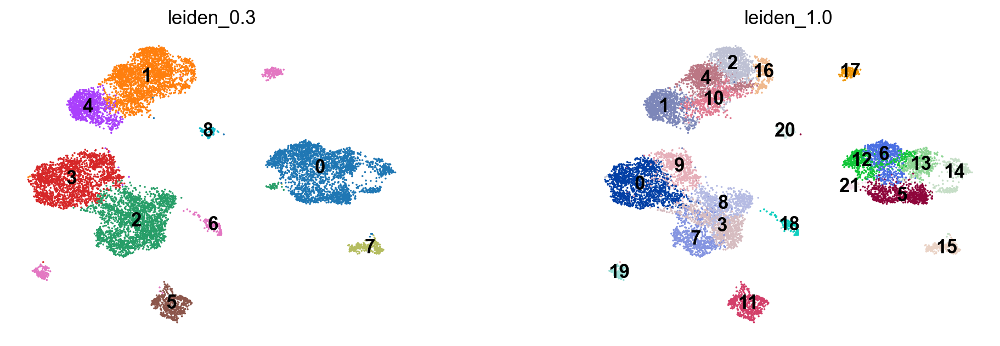

In [12]:
N_PCS = 30
sc.pp.neighbors(hw, n_neighbors=15, n_pcs=N_PCS, random_state=SEED)
sc.tl.umap(hw, min_dist=0.3, random_state=SEED)

RESOLUTIONS = (0.3, 1.0)
for r in RESOLUTIONS:
    sc.tl.leiden(hw, resolution=r, key_added=f"leiden_{r}", random_state=SEED)

sc.pl.umap(hw, color=[f"leiden_{r}" for r in RESOLUTIONS], legend_loc="on data", size=8, ncols=2, wspace=0.3)

In [13]:
sizes = pd.concat({f"res={r}": hw.obs[f"leiden_{r}"].value_counts().sort_index() for r in RESOLUTIONS}, axis=1)
display(sizes.fillna(0).astype(int))
print({f"res={r}": hw.obs[f"leiden_{r}"].nunique() for r in RESOLUTIONS})
display(pd.crosstab(hw.obs[f"leiden_{RESOLUTIONS[0]}"], hw.obs[f"leiden_{RESOLUTIONS[1]}"],
                    rownames=["res=0.3"], colnames=["res=1.0"]))

,res=0.3,res=1.0
0,2714,1565
1,2453,1004
2,2276,918
3,2053,808
4,1033,796
5,533,729
6,453,684
7,273,676
8,92,669
9,0,572


{'res=0.3': 9, 'res=1.0': 22}


res=1.0,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
res=0.3,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,728,683,0,0,0,...,504,454,340,0,0,0,0,0,1,3
1,4,30,899,0,788,0,1,0,0,0,...,0,0,0,0,220,0,0,0,0,0
2,67,0,1,805,0,1,0,676,666,23,...,0,0,0,0,0,0,0,0,0,37
3,1494,0,0,3,2,0,0,0,1,548,...,0,0,0,0,0,0,0,0,0,0
4,0,974,18,0,6,0,0,0,2,1,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,156,150,144,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,273,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,92,0


**Сравнение размеров.** При `resolution=0.3` получилось 9 кластеров (от 2 714 до 92 клеток), при `resolution=1.0` получилось 22 (от 1 565 до 40).

**Как `resolution` влияет на число кластеров:** чем оно больше, тем мельче нарезка. Крупные острова на UMAP остаются теми же, но внутри них появляются подгруппы.

**Какие кластеры разделились при увеличении разрешения** (по кросс-таблице):
- T-клетки (кластер 0 при 0.3, 2 714 клеток) распались на 5, 6, 12, 13 и 14: наивные и центральной памяти CD4 T, Tfh-подобные, Tfh и CD8 T.
- Делящиеся B-клетки (кластер 2 при 0.3, 2 276) распались на 3, 7 и 8: это разные фазы клеточного цикла.
- Остальные B-клетки (кластер 1 при 0.3, 2 453) распались на 2, 4, 10 и 16: покой, активация, стресс.
- B-клетки герминального центра (кластер 3 при 0.3, 2 053) распались на 0 и 9.
- Кластер 6 при 0.3 (453 клетки) распался на 17, 18 и 19. Все они из одного донора, см. задание 4.
- Не разделились: кластер 4 при 0.3 (почти целиком стал кластером 1), плазматические клетки (кластер 11), миелоидные (20) и кластер 7 при 0.3 (стал 15).

**Кластер не обязательно соответствует отдельному типу клеток:** кластеры 3, 7, 8 и 18 это делящиеся B-клетки в разных фазах цикла, то есть состояния одного типа. Кластеры 10 и 16 это B-клетки со стрессом от обработки ткани, а не отдельный тип. Кластеры 15, 17, 18 и 19 выделились из-за донора и технологии. Поэтому сначала смотрим маркеры и только потом решаем, перед нами тип, состояние или артефакт.

## Задание 4. Ручная аннотация

Выбираем разрешение 1.0 (22 кластера): оно разделяет T-клетки на подтипы (наивные, Tfh, CD8) и B-клетки на покоящиеся и герминальные, а при 0.3 эти различия слиты.

/opt/anaconda3/envs/sc_hw39/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:429: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/opt/anaconda3/envs/sc_hw39/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:431: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/opt/anaconda3/envs/sc_hw39/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:434: PerformanceWarning: DataFram

,n_cells,top_markers
cluster,,
0,1565,"PRPSAP2, MEF2B, RGS13, ACTG1, ELL3, CD40, SERF2, NEIL1"
1,1004,"HLA-DPA1, HLA-DPB1, BANK1, HLA-DRA, CD52, MS4A1, CD74, IFITM2"
2,918,"KLF2, BTG1, BANK1, TXNIP, PDE4B, CD69, CD24, HLA-DRB5"
3,808,"PKMYT1, TYMS, TK1, GINS2, CLSPN, UHRF1, MCM4, DHFR"
4,796,"CD83, PDE4B, TSC22D3, KLF2, CXCR4, SLC2A3, SARAF, NR4A2"
5,729,"GIMAP7, IL32, CD3D, CD3E, LINC00861, CD7, CD2, TCF7"
6,684,"MAF, SRGN, CD3E, TOX2, CD3D, CH25H, RNF19A, LAT"
7,676,"PLK1, CDC20, CENPE, CCNB2, CENPF, DLGAP5, HMMR, ASPM"
8,669,"TYMS, STMN1, DUT, MCM7, TUBA1B, GINS2, TK1, GAPDH"


,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
0,PRPSAP2,46.804001,3.121,0.0,0.0,0.833,0.321
1,MEF2B,44.014000,2.796,0.0,0.0,0.707,0.217
2,RGS13,43.070999,2.730,0.0,0.0,0.845,0.307
3,ACTG1,42.265999,1.470,0.0,0.0,0.996,0.953
4,ELL3,38.714001,2.479,0.0,0.0,0.682,0.241
5,CD40,38.063000,2.255,0.0,0.0,0.787,0.371
6,SERF2,36.591999,1.137,0.0,0.0,0.997,0.951
7,NEIL1,35.338001,2.259,0.0,0.0,0.666,0.259
8,MYO1E,35.259998,2.352,0.0,0.0,0.596,0.211
9,LAPTM5,34.932999,1.281,0.0,0.0,0.990,0.888


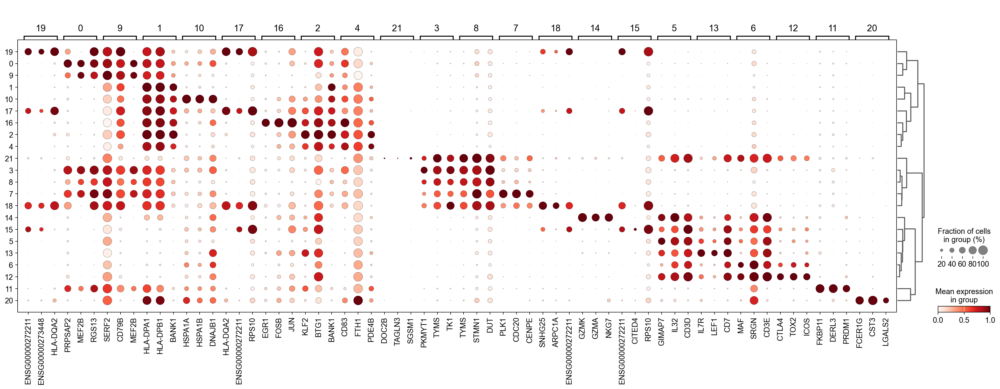

In [14]:
CLUSTER_KEY = "leiden_1.0"
clusters = list(hw.obs[CLUSTER_KEY].cat.categories)

sc.tl.rank_genes_groups(hw, groupby=CLUSTER_KEY, method="wilcoxon", reference="rest",
                        use_raw=False, tie_correct=True, pts=True, key_added="wilcoxon")

marker_tables = {}
for c in clusters:
    df = sc.get.rank_genes_groups_df(hw, group=c, key="wilcoxon")
    df = df[(df["pvals_adj"] < 0.05) & (df["logfoldchanges"] > 1) & (df["pct_nz_group"] > 0.25)]
    marker_tables[c] = df.sort_values("scores", ascending=False)

pd.set_option("display.max_colwidth", 120)
top_markers = pd.DataFrame({
    "cluster": clusters,
    "n_cells": [int((hw.obs[CLUSTER_KEY] == c).sum()) for c in clusters],
    "top_markers": [", ".join(marker_tables[c]["names"].head(8)) for c in clusters],
}).set_index("cluster")
display(top_markers)
display(marker_tables[clusters[0]].head(10).round(3))

sc.pl.rank_genes_groups_dotplot(hw, key="wilcoxon", groupby=CLUSTER_KEY, n_genes=3,
                                use_raw=False, standard_scale="var")

### Маркеры лимфоидной ткани

Панели составлены по литературе о миндалинах и лимфоузлах - было подсказано, где искать с помощью ИИ. Что учитывать:

- **Наивные B:** `IGHD`, `TCL1A`, `FCER2`, `IL4R`. **Памяти:** `CD27`, `TNFRSF13B`, `AIM2`. **Герминального центра (GC):** `BCL6`, `RGS13`, `MEF2B`, `LMO2` и пролиферация (`MKI67`). **Плазматические:** `JCHAIN`, `MZB1`, `XBP1`.
- **Tfh:** `CXCL13`, `PDCD1`, `ICOS`, `CXCR5`, `TOX2`. **Treg:** `FOXP3`, `IL2RA`, `CTLA4`.
- **Ограничения:** `NKG7` и `GZMK` бывают и у CD8 T, и у NK; `CCR7` есть у наивных и центральной памяти T; `MKI67` отмечает деление, а не тип; `CTLA4` высок и у Tfh, и у Treg.

**Откуда взяты маркеры.**

- Наивные и покоящиеся B (`IGHD`, `TCL1A`, `FCER2`, `IL4R`, `MS4A1`) и B-клетки герминального центра (`BCL6`, `RGS13`, `MEF2B`, `LMO2`, `SERPINA9`, `CD40`): King et al. 2021 и Massoni-Badosa et al. 2024 (атлас миндалины).
- Плазматические клетки (`XBP1`, `PRDM1`, `JCHAIN`, `MZB1`, `DERL3`): King et al. 2021.
- Tfh (`CXCR5`, `PDCD1`, `ICOS`, `CXCL13`, `TOX2`, `MAF`): Massoni-Badosa et al. 2024.
- Наивные T (`CCR7`, `LEF1`, `SELL`, `TCF7`, `IL7R`), CD8 T памяти (`CD8A`, `CD8B`, `GZMK`, `CCL5`, `EOMES`) и миелоидные клетки (`LYZ`, `CST3`, `TYROBP`, `CD14`): Domínguez Conde et al. 2022 (на ней обучена модель CellTypist).
- Делящиеся клетки (`MKI67`, `TOP2A`, `PLK1`, `CCNB2`, `TYMS`): стандартные гены клеточного цикла.
- Стресс при обработке ткани (`FOS`, `JUN`, `EGR1`, `HSPA1A`, `DNAJB1`): van den Brink et al. 2017. Это не тип клеток.

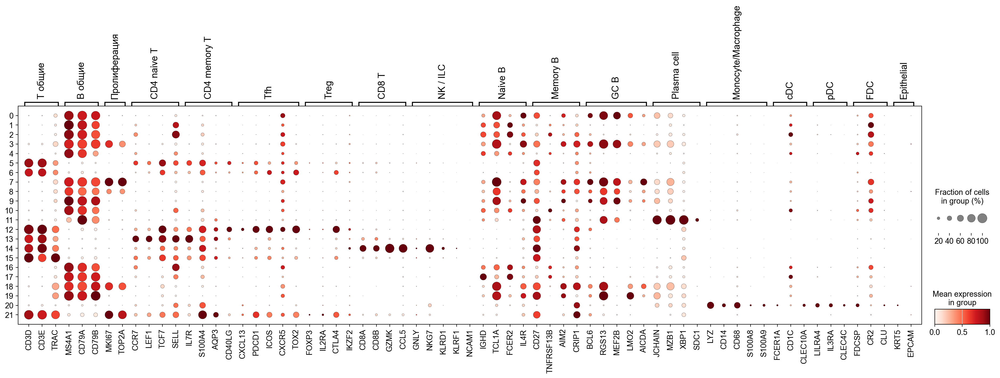

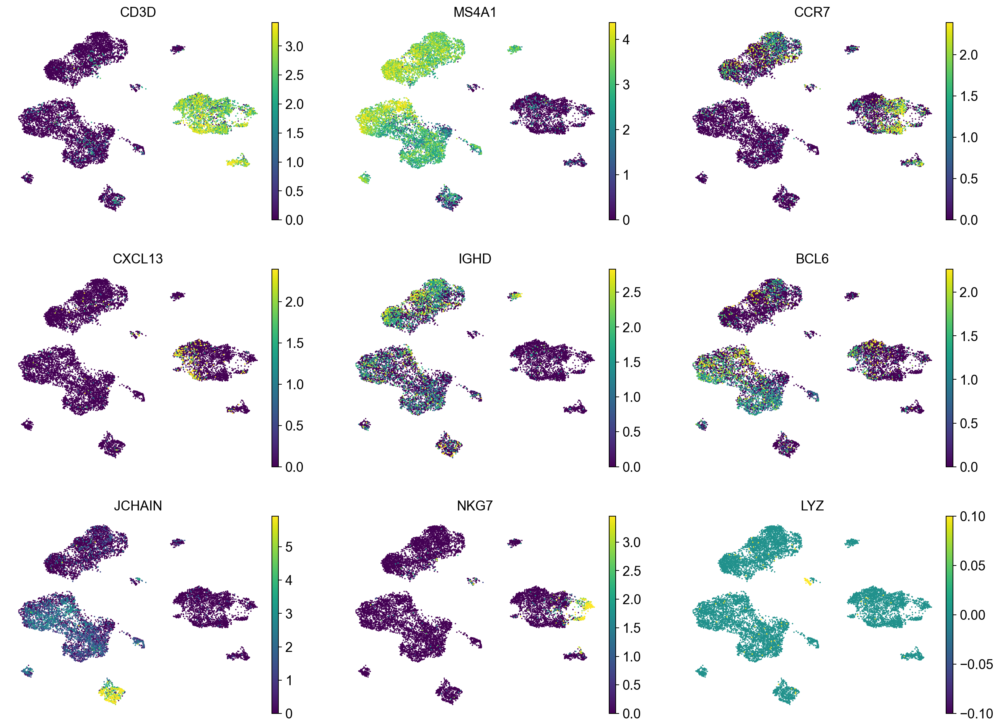

In [15]:
PANELS = {
    "CD4 naive T":       ["CCR7", "LEF1", "TCF7", "SELL"],
    "CD4 memory T":      ["IL7R", "S100A4", "AQP3", "CD40LG"],
    "Tfh":               ["CXCL13", "PDCD1", "ICOS", "CXCR5", "TOX2"],
    "Treg":              ["FOXP3", "IL2RA", "CTLA4", "IKZF2"],
    "CD8 T":             ["CD8A", "CD8B", "GZMK", "CCL5"],
    "NK / ILC":          ["GNLY", "NKG7", "KLRD1", "KLRF1", "NCAM1"],
    "Naive B":           ["IGHD", "TCL1A", "FCER2", "IL4R"],
    "Memory B":          ["CD27", "TNFRSF13B", "AIM2", "CRIP1"],
    "GC B":              ["BCL6", "RGS13", "MEF2B", "LMO2", "AICDA"],
    "Plasma cell":       ["JCHAIN", "MZB1", "XBP1", "SDC1"],
    "Monocyte/Macrophage": ["LYZ", "CD14", "CD68", "S100A8", "S100A9"],
    "cDC":               ["FCER1A", "CD1C", "CLEC10A"],
    "pDC":               ["LILRA4", "IL3RA", "CLEC4C"],
    "FDC":               ["FDCSP", "CR2", "CLU"],
    "Epithelial":        ["KRT5", "KRT19", "EPCAM"],
}
PANELS = {k: [g for g in v if g in hw.var_names] for k, v in PANELS.items()}
PANELS = {k: v for k, v in PANELS.items() if v}
GENERAL = {"T общие": [g for g in ["CD3D", "CD3E", "TRAC"] if g in hw.var_names],
           "B общие": [g for g in ["MS4A1", "CD79A", "CD79B"] if g in hw.var_names],
           "Пролиферация": [g for g in ["MKI67", "TOP2A"] if g in hw.var_names]}

sc.pl.dotplot(hw, var_names={**GENERAL, **PANELS}, groupby=CLUSTER_KEY, standard_scale="var",
              use_raw=False, figsize=(26, 6))

umap_genes = [g for g in ["CD3D", "MS4A1", "CCR7", "CXCL13", "IGHD", "BCL6", "JCHAIN", "NKG7", "LYZ"]
              if g in hw.var_names]
sc.pl.umap(hw, color=umap_genes, ncols=3, size=8, use_raw=False, vmax="p99")

### Присвоение типов

Сначала по панелям маркеров для каждого кластера считается score, и предлагается тип с максимальным значением. Автоматика ошиблась:

- 11 кластеров из 22 (5 448 клеток, 46 %) получили `Unknown`, хотя по маркерам их можно определить. Часть из них неопределённая из-за ничьей двух панелей: кластер 12 (Tfh и Treg почти поровну), кластер 14 (CD8 T и NK), кластер 20 (моноциты и pDC);
- кластер 4 назван `FDC`, но `FDCSP` в нём почти нет, зато есть `CD83`, `CXCR4`, `NR4A2`: это активированные B-клетки;
- кластер 17 назван `cDC`, но `FCER1A` и `CLEC10A` в нём нет, зато есть `MS4A1` и `IGHD`: это B-клетки (`CD1C` бывает и у B-клеток);
- кластер 21 назван `Treg`, но у него высоки `MKI67`, `TOP2A` и `CD3D`: это делящиеся T-клетки.

Поэтому итоговый тип выбран вручную по топ-маркерам кластера (таблица `top_markers`), по dotplot и по согласованности с CellTypist (раздел 5). Автоматическое предложение оставлено в таблице для сравнения.

In [16]:
score_cols = {}
for name, genes in PANELS.items():
    col = "pscore_" + "".join(ch if ch.isalnum() else "_" for ch in name)
    sc.tl.score_genes(hw, gene_list=genes, score_name=col, use_raw=False, random_state=SEED)
    score_cols[name] = col

cluster_scores = hw.obs.groupby(CLUSTER_KEY, observed=True)[list(score_cols.values())].mean()
cluster_scores.columns = list(score_cols.keys())
z = (cluster_scores - cluster_scores.mean()) / cluster_scores.std(ddof=0)

suggest = {}
for c in clusters:
    s = z.loc[c].sort_values(ascending=False)
    suggest[c] = s.index[0] if (s.iloc[0] > 1.0 and s.iloc[0] - s.iloc[1] > 0.3) else "Unknown"
display(z.round(2).assign(предложение=pd.Series(suggest)))

,CD4 naive T,CD4 memory T,Tfh,Treg,CD8 T,NK / ILC,Naive B,Memory B,GC B,Plasma cell,Monocyte/Macrophage,cDC,pDC,FDC,Epithelial,предложение
leiden_1.0,,,,,,,,,,,,,,,,
0,-0.96,-0.87,-0.45,-0.54,-0.32,-0.35,0.97,-0.36,1.90,0.02,-0.20,-0.18,-0.27,0.35,-0.15,GC B
1,0.20,-0.44,-0.35,-0.46,-0.29,-0.28,1.40,-1.30,-0.55,-0.35,-0.16,1.01,-0.03,1.56,-0.37,Unknown
2,0.26,-0.60,-0.44,-0.52,-0.34,-0.35,1.16,-0.84,-0.75,-0.38,-0.16,1.42,0.04,0.80,-0.39,Unknown
3,-1.18,-1.06,-0.79,-0.69,-0.39,-0.43,0.44,-0.63,1.36,-0.02,-0.28,-0.64,-0.33,-0.36,0.33,GC B
4,-0.08,-0.43,-0.17,-0.32,-0.26,-0.26,0.94,-0.66,-0.43,-0.27,-0.13,1.15,-0.09,1.90,-0.35,FDC
5,1.76,1.90,1.21,0.48,-0.02,-0.02,-1.08,1.06,-0.59,-0.39,-0.24,-0.73,-0.28,-0.72,-0.35,Unknown
6,0.43,0.77,2.08,1.75,-0.08,-0.25,-0.92,0.35,-0.56,-0.31,-0.20,-0.65,-0.28,-0.47,-0.36,Tfh
7,-1.21,-1.07,-0.72,-0.69,-0.37,-0.39,0.73,-0.51,1.72,-0.00,-0.25,-0.50,-0.29,0.12,-0.14,GC B
8,-0.95,-0.83,-0.75,-0.67,-0.31,-0.36,0.10,-0.81,0.79,-0.07,-0.22,-0.34,-0.25,-0.26,0.80,Unknown


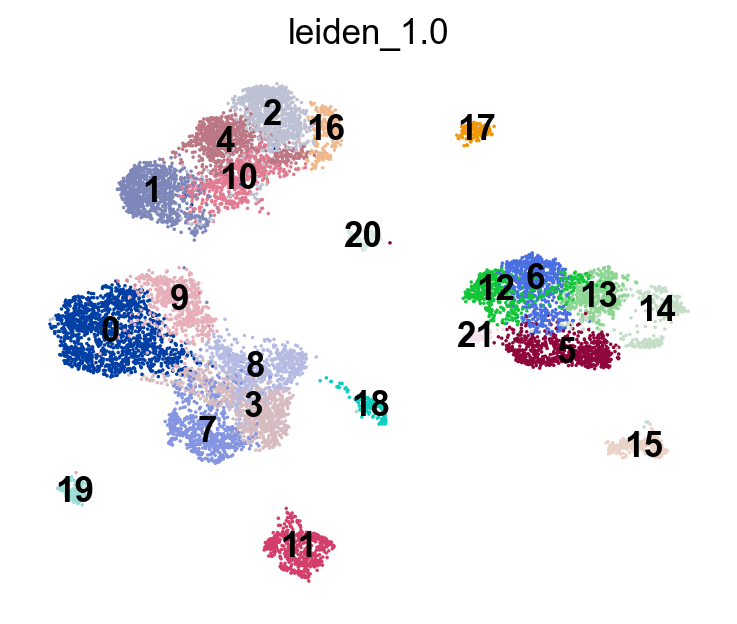

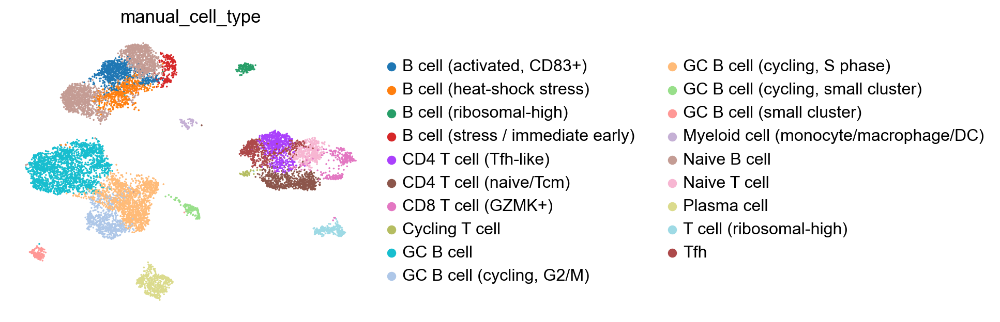

manual_cell_type
GC B cell                                2137
Naive B cell                             1922
GC B cell (cycling, S phase)             1477
B cell (activated, CD83+)                 796
CD4 T cell (naive/Tcm)                    729
CD4 T cell (Tfh-like)                     684
GC B cell (cycling, G2/M)                 676
B cell (heat-shock stress)                548
Plasma cell                               537
Tfh                                       504
Naive T cell                              454
CD8 T cell (GZMK+)                        340
T cell (ribosomal-high)                   273
B cell (stress / immediate early)         220
B cell (ribosomal-high)                   156
GC B cell (cycling, small cluster)        150
GC B cell (small cluster)                 144
Myeloid cell (monocyte/macrophage/DC)      93
Cycling T cell                             40


,Кластер,Клеток,Предполагаемый клеточный тип,Маркерные гены,Обоснование,Авто-предложение
0,0,1565,GC B cell,"MEF2B, RGS13, CD40, ELL3, PRPSAP2","Высокие MEF2B, RGS13, CD40 (маркеры B-клеток герминального центра), BCL6+, нет MKI67; CellTypist: GC B cells (1 304 из 1 565).",GC B
1,1,1004,Naive B cell,"MS4A1, BANK1, CD74, HLA-DRA, TCL1A, FCER2","B-клетки (MS4A1, BANK1, CD79A/B) с TCL1A и FCER2 и без маркеров GC и делящихся клеток: наивные/покоящиеся; CellTypist: Naive B (651), Memory B (260).",Unknown
2,2,918,Naive B cell,"KLF2, BANK1, TXNIP, CD69, FCER2","Покоящиеся B-клетки: KLF2, TXNIP, BTG1 (программа покоя), FCER2+, нет GC и делящихся; CellTypist: Naive B (532), Memory B (294).",Unknown
3,3,808,"GC B cell (cycling, S phase)","PKMYT1, TYMS, TK1, MCM4, GINS2","Гены S-фазы (TYMS, TK1, MCM4, GINS2) на фоне GC B-клеток; CellTypist: Proliferative GC B (424), GC B (324).",GC B
4,4,796,"B cell (activated, CD83+)","CD83, CXCR4, NR4A2, TSC22D3, PDE4B","B-клетки (MS4A1+, CD79+) с CD83, CXCR4, NR4A2: ранняя активация; почти нет FDCSP (не FDC), нет GC и делящихся; CellTypist: Naive B (467), Memory B (237).",FDC
5,5,729,CD4 T cell (naive/Tcm),"CD3D, CD3E, IL32, TCF7, IL7R, GIMAP7","T-клетки (CD3D/E+), без CD8A/B и цитотоксических генов, IL7R+, TCF7+: CD4 T наивные и центральной памяти; CellTypist: Tcm/Naive helper T (249), Treg (243), Tfh (95).",Unknown
6,6,684,CD4 T cell (Tfh-like),"MAF, TOX2, CH25H, CD3E, SRGN","CD4 T с MAF и TOX2 (программа Tfh), CXCR5 и PDCD1 умеренные; FOXP3 и IL2RA не детектируются, поэтому не Treg, несмотря на метку CellTypist Treg (350).",Tfh
7,7,676,"GC B cell (cycling, G2/M)","PLK1, CDC20, CENPE, CCNB2, CENPF, MKI67, TOP2A","Гены G2/M фазы и MKI67/TOP2A при B-клеточном профиле (CD79, MS4A1); CellTypist: Proliferative GC B (539).",GC B
8,8,669,"GC B cell (cycling, S phase)","TYMS, STMN1, MCM7, TUBA1B, DUT","Гены S-фазы и деления при GC B профиле; CellTypist: Proliferative GC B (420), GC B (120).",Unknown
9,9,572,GC B cell,"MEF2B, SERPINA9, CD79B, ELL3, MS4A1","MEF2B, SERPINA9, BCL6 (GC B-клетки), без маркеров деления; CellTypist: GC B (462).",GC B


In [17]:
# Итоговая ручная аннотация: (тип, маркерные гены, обоснование) для каждого кластера leiden_1.0
ANNOT = {
    "0":  ("GC B cell", "MEF2B, RGS13, CD40, ELL3, PRPSAP2",
           "Высокие MEF2B, RGS13, CD40 (маркеры B-клеток герминального центра), BCL6+, нет MKI67; CellTypist: GC B cells (1 304 из 1 565)."),
    "1":  ("Naive B cell", "MS4A1, BANK1, CD74, HLA-DRA, TCL1A, FCER2",
           "B-клетки (MS4A1, BANK1, CD79A/B) с TCL1A и FCER2 и без маркеров GC и делящихся клеток: наивные/покоящиеся; CellTypist: Naive B (651), Memory B (260)."),
    "2":  ("Naive B cell", "KLF2, BANK1, TXNIP, CD69, FCER2",
           "Покоящиеся B-клетки: KLF2, TXNIP, BTG1 (программа покоя), FCER2+, нет GC и делящихся; CellTypist: Naive B (532), Memory B (294)."),
    "3":  ("GC B cell (cycling, S phase)", "PKMYT1, TYMS, TK1, MCM4, GINS2",
           "Гены S-фазы (TYMS, TK1, MCM4, GINS2) на фоне GC B-клеток; CellTypist: Proliferative GC B (424), GC B (324)."),
    "4":  ("B cell (activated, CD83+)", "CD83, CXCR4, NR4A2, TSC22D3, PDE4B",
           "B-клетки (MS4A1+, CD79+) с CD83, CXCR4, NR4A2: ранняя активация; почти нет FDCSP (не FDC), нет GC и делящихся; CellTypist: Naive B (467), Memory B (237)."),
    "5":  ("CD4 T cell (naive/Tcm)", "CD3D, CD3E, IL32, TCF7, IL7R, GIMAP7",
           "T-клетки (CD3D/E+), без CD8A/B и цитотоксических генов, IL7R+, TCF7+: CD4 T наивные и центральной памяти; CellTypist: Tcm/Naive helper T (249), Treg (243), Tfh (95)."),
    "6":  ("CD4 T cell (Tfh-like)", "MAF, TOX2, CH25H, CD3E, SRGN",
           "CD4 T с MAF и TOX2 (программа Tfh), CXCR5 и PDCD1 умеренные; FOXP3 и IL2RA не детектируются, поэтому не Treg, несмотря на метку CellTypist Treg (350)."),
    "7":  ("GC B cell (cycling, G2/M)", "PLK1, CDC20, CENPE, CCNB2, CENPF, MKI67, TOP2A",
           "Гены G2/M фазы и MKI67/TOP2A при B-клеточном профиле (CD79, MS4A1); CellTypist: Proliferative GC B (539)."),
    "8":  ("GC B cell (cycling, S phase)", "TYMS, STMN1, MCM7, TUBA1B, DUT",
           "Гены S-фазы и деления при GC B профиле; CellTypist: Proliferative GC B (420), GC B (120)."),
    "9":  ("GC B cell", "MEF2B, SERPINA9, CD79B, ELL3, MS4A1",
           "MEF2B, SERPINA9, BCL6 (GC B-клетки), без маркеров деления; CellTypist: GC B (462)."),
    "10": ("B cell (heat-shock stress)", "HSPA1A, HSPA1B, DNAJB1, HSPA6, TNFRSF13B",
           "B-клетки (BANK1, MS4A1) с белками теплового шока: стресс при диссоциации ткани, а не отдельный тип; CellTypist: Naive B (279), Memory B (157)."),
    "11": ("Plasma cell", "XBP1, PRDM1, FKBP11, DERL3, JCHAIN, MZB1",
           "Классические гены плазматических клеток, MS4A1 низкий; CellTypist: Plasma cells (500 из 537)."),
    "12": ("Tfh", "PDCD1, ICOS, CXCR5, CXCL13, CTLA4, TOX2",
           "Профиль T фолликулярных хелперов: PDCD1, ICOS, CXCR5, CXCL13, TOX2; FOXP3 отсутствует (метка CellTypist Treg (332) не подтверждается); CellTypist: Tfh (157)."),
    "13": ("Naive T cell", "IL7R, LEF1, CCR7, SELL, TCF7, CD7",
           "CCR7, SELL, LEF1, TCF7 и IL7R: наивные T; по CellTypist смесь CD4 (Tcm/Naive helper, 222) и CD8 (Tcm/Naive cytotoxic, 104), поэтому CD4/CD8 не указан."),
    "14": ("CD8 T cell (GZMK+)", "GZMK, GZMA, CD8A, CD8B, CCL5, NKG7, EOMES",
           "CD8A/B, GZMK, EOMES, CCL5: CD8 T памяти с цитотоксическим профилем; CellTypist: Tem/Trm cytotoxic (264 из 340)."),
    "15": ("T cell (ribosomal-high)", "CD3D, TRAC, RPS10, RPL13A, APBA2",
           "CD3D/TRAC+, высоки рибосомные гены, среди маркеров много генов без символа (ENSG…): малый отдельный остров; CellTypist: Treg/Tcm-naive helper."),
    "16": ("B cell (stress / immediate early)", "EGR1, FOSB, JUN, FOS, CD69, DUSP1",
           "B-клетки (MS4A1+) с генами немедленного раннего ответа: артефакт диссоциации/ранняя активация; CellTypist: Naive B (128), Memory B (85)."),
    "17": ("B cell (ribosomal-high)", "IGHD, MS4A1, RPS10, RPL13A, HLA-DQA2",
           "B-клетки (IGHD+, MS4A1+), нет FCER1A и CLEC10A (это не cDC), рибосомные гены и гены без символа, малый отдельный остров; CellTypist: Naive B (81), Memory B (54)."),
    "18": ("GC B cell (cycling, small cluster)", "MKI67, TOP2A, CD79B, SNHG25",
           "B-клетки с MKI67/TOP2A; среди маркеров гены без символа, малый отдельный остров; CellTypist: Proliferative GC B (131)."),
    "19": ("GC B cell (small cluster)", "LMO2, RGS13, MEF2B, HLA-DQA2",
           "LMO2 и RGS13 (GC B-клетки), без маркеров деления; малый отдельный остров; CellTypist: GC B (124 из 144)."),
    "20": ("Myeloid cell (monocyte/macrophage/DC)", "LYZ, CST3, TYROBP, FCER1G, MS4A6A, CD14, CD68",
           "Миелоидные гены (LYZ, CST3, TYROBP, MS4A6A), нет лимфоидных; внутри есть pDC (LILRA4, IL3RA) и DC2/моноциты (CellTypist: DC2, pDC и др.), для одного типа клеток слишком мало (93)."),
    "21": ("Cycling T cell", "CD3D, CD3E, TRAC, MKI67, TOP2A, MT1E",
           "T-клеточные гены (CD3D/E, TRAC) вместе с MKI67, TOP2A, CENPF: делящиеся T-клетки; автоматика назвала Treg, что неверно."),
}

# проверка - таблица составлена для конкретных размеров кластеров. Если кластеры другие, названия применять нельзя.
EXPECTED_SIZES = {"0": 1565, "1": 1004, "2": 918, "3": 808, "4": 796, "5": 729, "6": 684, "7": 676, "8": 669,
                  "9": 572, "10": 548, "11": 537, "12": 504, "13": 454, "14": 340, "15": 273, "16": 220,
                  "17": 156, "18": 150, "19": 144, "20": 93, "21": 40}
actual_sizes = {str(k): int(v) for k, v in hw.obs[CLUSTER_KEY].value_counts().items()}
if actual_sizes != EXPECTED_SIZES:
    raise ValueError("Размеры кластеров отличаются от тех, для которых составлена таблица ANNOT. "
                     "Запустите ноутбук с начала (Restart & Run All) в том же окружении или пересоставьте ANNOT по маркерам.")

auto_suggestion = dict(suggest)                         # автоматическое предложение из ячейки выше
manual_annotations = {c: ANNOT[c][0] for c in clusters}
hw.obs["manual_cell_type"] = pd.Categorical(hw.obs[CLUSTER_KEY].astype(str).map(manual_annotations))

sc.pl.umap(hw, color=CLUSTER_KEY, size=8, legend_loc="on data")
sc.pl.umap(hw, color="manual_cell_type", size=8)
print(hw.obs["manual_cell_type"].value_counts().to_string())

annotation_table = pd.DataFrame([{
    "Кластер": c,
    "Клеток": EXPECTED_SIZES[c],
    "Предполагаемый клеточный тип": ANNOT[c][0],
    "Маркерные гены": ANNOT[c][1],
    "Обоснование": ANNOT[c][2],
    "Авто-предложение": auto_suggestion[c],
} for c in clusters])
pd.set_option("display.max_colwidth", 250)
display(annotation_table)

Для каждого кластера указан тип, ключевые гены и обоснование: какие гены есть, каких нет и что говорит CellTypist (числа взяты из таблицы сопряжённости в разделе 5). Последний столбец показывает, что предложила автоматика, чтобы было видно, где она ошиблась.

**Итог по клеткам** (11 880 клеток): B-клетки герминального центра, включая делящиеся, 4 584 (38,6 %); покоящиеся, наивные и активированные B-клетки 3 642 (30,7 %); T-клетки 3 024 (25,5 %); плазматические клетки 537 (4,5 %); миелоидные клетки 93 (0,8 %).

У кластеров 15, 17, 18 и 19 тип ясен (T или B), но они малые, и их состояние описать трудно. Отдельных кластеров NK и ILC нет: CellTypist помечает лишь около 25 клеток как NK и 26 как ILC3, они растворены в других кластерах.

## Задание 5. Автоматическая аннотация (CellTypist)

Модель `Immune_All_Low.pkl` обучена на иммунных клетках человека из разных тканей и различает тонкие подтипы. Миндалины почти целиком состоят из иммунных клеток, поэтому она подходит. Ограничение: неиммунных клеток (эпителий, стромальные клетки, FDC) в референсе нет, и такие клетки получат ближайшую иммунную метку с низкой уверенностью. CellTypist ждёт лог-нормализованную матрицу (сумма 10 000 и `log1p`), она у нас в `hw.X`.

📂 Storing models in /Users/anna.shifon/.celltypist/data/models
💾 Total models to download: 1
⏩ Skipping [1/1]: Immune_All_Low.pkl (file exists)
🔬 Input data has 11880 cells and 17335 genes
🔗 Matching reference genes in the model
🧬 4891 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


,cells
celltypist,
Germinal center B cells,2474
Naive B cells,2383
Proliferative germinal center B cells,1574
Memory B cells,1278
Regulatory T cells,1129
Tcm/Naive helper T cells,632
Follicular helper T cells,517
Plasma cells,507
Age-associated B cells,433


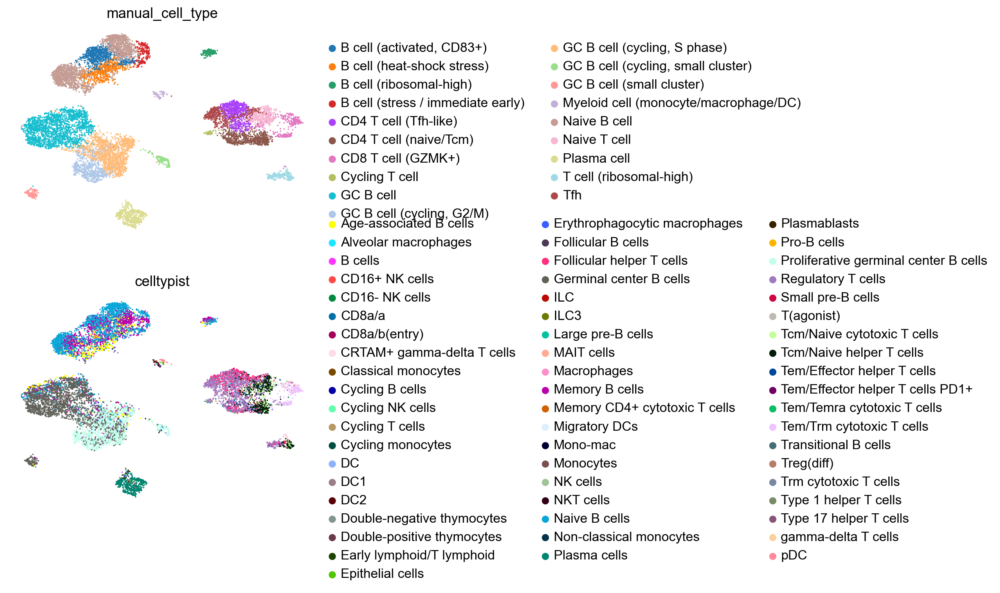

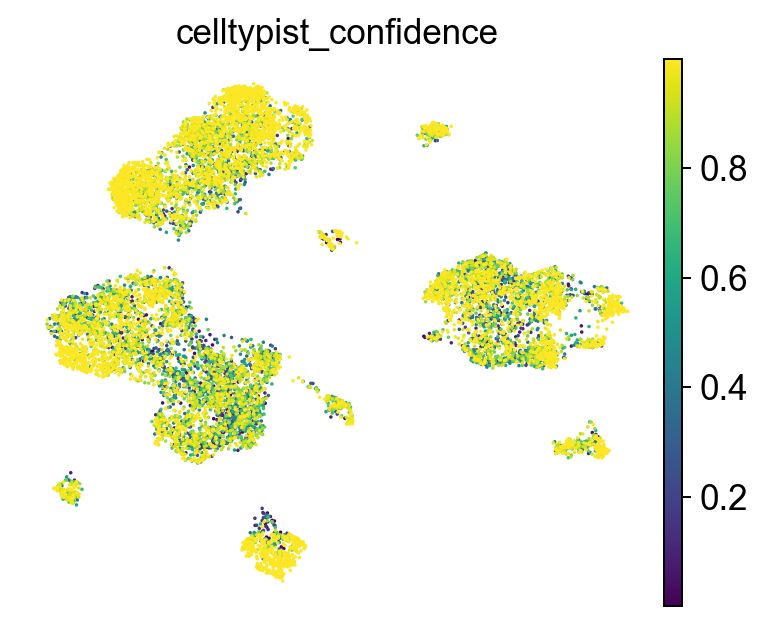

In [18]:
import celltypist
from celltypist import models

models.download_models(model="Immune_All_Low.pkl", force_update=False)
model = models.Model.load("Immune_All_Low.pkl")

prediction = celltypist.annotate(hw.copy(), model=model, majority_voting=False)
labels = prediction.predicted_labels["predicted_labels"].reindex(hw.obs_names)
assert labels.notna().all()
hw.obs["celltypist"] = pd.Categorical(labels.astype(str).to_numpy())
hw.obs["celltypist_confidence"] = (prediction.probability_matrix.max(axis=1)
                                   .reindex(hw.obs_names).astype(float).to_numpy())
display(hw.obs["celltypist"].value_counts().to_frame("cells").head(20))

sc.pl.umap(hw, color=["manual_cell_type", "celltypist"], ncols=1, size=8)
sc.pl.umap(hw, color="celltypist_confidence", cmap="viridis", size=8)

In [19]:
common = hw.obs["celltypist"].value_counts(normalize=True)
common = common[common > 0.01].index

def squeeze(ct):
    return pd.concat([ct[common], ct.drop(columns=common).sum(axis=1).rename("other")], axis=1)

print("Кластер Leiden × CellTypist")
display(squeeze(pd.crosstab(hw.obs[CLUSTER_KEY], hw.obs["celltypist"], rownames=["Leiden"], colnames=["CellTypist"])))
print("Ручная аннотация × CellTypist")
display(squeeze(pd.crosstab(hw.obs["manual_cell_type"], hw.obs["celltypist"], rownames=["Manual"], colnames=["CellTypist"])))

Кластер Leiden × CellTypist


,Germinal center B cells,Naive B cells,Proliferative germinal center B cells,Memory B cells,Regulatory T cells,Tcm/Naive helper T cells,Follicular helper T cells,Plasma cells,Age-associated B cells,Tem/Trm cytotoxic T cells,Tcm/Naive cytotoxic T cells,other
Leiden,,,,,,,,,,,,
0,1304,108,26,68,2,0,0,1,37,0,0,19
1,6,651,8,260,2,0,1,0,70,0,0,6
2,2,532,2,294,0,0,0,0,87,0,0,1
3,324,14,424,10,7,0,1,2,7,0,0,19
4,4,467,0,237,0,0,1,0,75,0,1,11
5,0,2,0,10,243,249,95,1,0,7,45,77
6,1,8,2,25,350,47,201,0,0,4,6,40
7,105,10,539,6,1,0,0,1,4,0,0,10
8,120,35,420,41,2,2,0,1,20,0,0,28


Ручная аннотация × CellTypist


,Germinal center B cells,Naive B cells,Proliferative germinal center B cells,Memory B cells,Regulatory T cells,Tcm/Naive helper T cells,Follicular helper T cells,Plasma cells,Age-associated B cells,Tem/Trm cytotoxic T cells,Tcm/Naive cytotoxic T cells,other
Manual,,,,,,,,,,,,
"B cell (activated, CD83+)",4,467,0,237,0,0,1,0,75,0,1,11
B cell (heat-shock stress),6,279,0,157,4,2,0,0,91,0,0,9
B cell (ribosomal-high),0,81,1,54,0,0,1,0,13,0,0,6
B cell (stress / immediate early),0,128,0,85,0,0,0,0,5,0,0,2
CD4 T cell (Tfh-like),1,8,2,25,350,47,201,0,0,4,6,40
CD4 T cell (naive/Tcm),0,2,0,10,243,249,95,1,0,7,45,77
CD8 T cell (GZMK+),1,0,0,0,29,2,0,0,0,264,5,39
Cycling T cell,0,2,2,0,24,1,1,0,0,0,0,10
GC B cell,1766,165,36,92,2,0,0,2,51,0,0,23


,Cycling,Naive,GC,TfH,MBC,DZ GC,Plasmablast,CD4+ NCM,MBC FCRL4+,Activated,CD8+ Cytotoxic,CD4+,other
Manual,,,,,,,,,,,,,
"B cell (activated, CD83+)",5,357,10,1,182,4,2,0,73,121,1,0,40
B cell (heat-shock stress),6,323,8,3,47,2,1,1,98,21,6,0,32
B cell (ribosomal-high),1,74,0,0,37,1,0,0,16,20,1,0,6
B cell (stress / immediate early),0,13,0,0,17,0,0,0,3,184,0,0,3
CD4 T cell (Tfh-like),1,0,0,442,0,0,0,28,0,0,7,71,135
CD4 T cell (naive/Tcm),1,0,0,296,0,0,1,194,0,0,13,68,156
CD8 T cell (GZMK+),0,0,0,1,0,0,0,3,0,0,279,0,57
Cycling T cell,3,0,0,2,0,0,0,0,0,0,1,0,34
GC B cell,59,7,1199,0,4,570,6,0,5,2,0,0,285


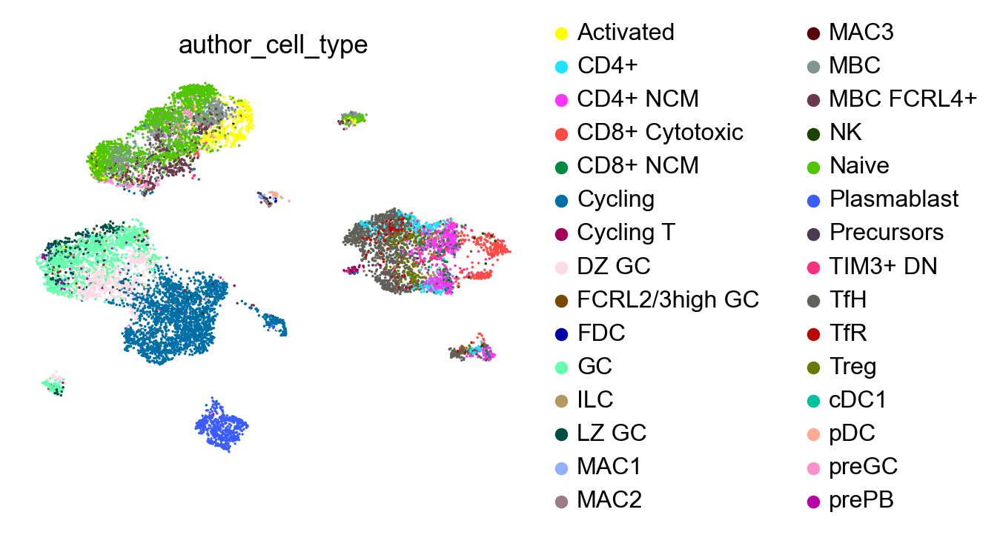

In [20]:
# Бонус: метки самих авторов (author_cell_type) как третья точка зрения
AUTHOR_COL = "author_cell_type" if "author_cell_type" in hw.obs.columns else None
if AUTHOR_COL:
    ct = pd.crosstab(hw.obs["manual_cell_type"], hw.obs[AUTHOR_COL], rownames=["Manual"], colnames=["Authors"])
    top_author = hw.obs[AUTHOR_COL].value_counts().index[:12]
    display(pd.concat([ct[top_author], ct.drop(columns=top_author).sum(axis=1).rename("other")], axis=1))
    sc.pl.umap(hw, color=[AUTHOR_COL], size=8)
else:
    print("Колонка author_cell_type не найдена")

**Результаты**

**Где ручная и автоматическая аннотации совпали:**
- плазматические клетки (кластер 11): 500 из 537 клеток CellTypist назвал Plasma cells;
- B-клетки герминального центра (кластеры 0, 9, 19): Germinal center B cells, 1 304 из 1 565, 462 из 572 и 124 из 144;
- делящиеся GC B (кластеры 3, 7, 8, 18): Proliferative germinal center B cells (424, 539, 420 и 131), совпало даже состояние;
- CD8 T (кластер 14): Tem/Trm cytotoxic T cells, 264 из 340;
- миелоидные клетки (кластер 20): около 40 % получили DC2, остальные редкие миелоидные метки (в таблице сопряжённости они попали в other).

**Где они расходятся:**
- **Tfh и Treg.** Кластеры 6 и 12 мы назвали Tfh-подобными и Tfh, а CellTypist большую часть отнёс к Regulatory T cells (350 из 684 и 332 из 504) и меньшую к Follicular helper T cells (201 и 157). Но `FOXP3` и `IL2RA` в этих кластерах практически не детектируются, а `PDCD1`, `ICOS`, `TOX2` высокие. Метки самих авторов датасета тоже за Tfh: у них 442 из 684 и 327 из 504 клеток это TfH. Здесь права ручная аннотация. Кластер 5 тоже спорный: мы назвали его наивными и центральной памяти CD4 T, а авторы датасета у 296 из 729 клеток ставят TfH.
- **Naive, Memory и Age-associated B.** В покоящихся B-кластерах CellTypist делит клетки примерно на Naive B (51-65 %), Memory B (26-39 %) и Age-associated B (7-17 %), а мы дали одну метку на кластер. Age-associated B для детских миндалин выглядит сомнительно.
- **Стресс.** Кластеры 10 и 16 CellTypist метит как обычные naive и memory B: он оценивает тип, а не состояние.
- **Кластеры 15, 17, 18, 19.** Типы CellTypist разумные (T или B), но кластеры малые, и тонкие метки по ним ненадёжны.

**С чем связаны расхождения:** Разная детализация меток; референс обучен на других тканях, донорах и платформах; CellTypist классифицирует клетки по одной, а кластеры строятся по графу соседей; наши панели короткие.

**Какая аннотация обоснованнее:** для Tfh и Treg, стрессовых состояний и малых кластеров ручная, потому что её можно проверить конкретными генами. Для разделения GC B и делящихся GC B, а также naive и memory B детальнее CellTypist. Лучше использовать вместе: CellTypist как гипотезу, маркеры как проверку.

## Задание 6. Субкластеризация

Берем кластер 13 (454 клетки, `Naive T cell`): `IL7R`, `LEF1`, `CCR7`, `SELL`. Выбран, потому что CellTypist разнёс его по разным меткам: Tcm/Naive helper T (222 клетки) и Tcm/Naive cytotoxic T (104). Значит, внутри, вероятно, и CD4, и CD8, и разные состояния. На общей карте это не видно: главные оси PCA заняты различиями между B, T и миелоидными клетками.

Для подмножества возвращаем сырые счётчики, заново выбираем HVG, нормализуем, и только потом PCA, граф, UMAP и Leiden. Иначе HVG останутся прежними (они разделяют B и T), и различия внутри T-клеток не попадут в анализ.

Субкластеризуем: ['13'] ['Naive T cell']
AnnData object with n_obs × n_vars = 454 × 17335
    obs: 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'percent.ribo', 'donor_id', 'Sample', 'assay_ontology_term_id', 'Status', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'ScrubletPrediction', 'DoubletFinderPrediction', 'ChainStatus', 'author_cell_type', 'barcode', 'Lineage', 'SEQUENCE_ID', 'IGH_FUNCTIONAL', 'IGH_IN_FRAME', 'IGH_STOP', 'IGH_V_CALL_GENOTYPED', 'IGH_D_CALL', 'IGH_J_CALL', 'IGH_JUNCTION_LENGTH', 'ISOTYPE', 'CLONE_ID', 'IGK_C_Gene', 'IGK_VDJ_Gene', 'IGK_FullLength', 'IGK_Productive', 'IGL_C_Gene', 'IGL_VDJ_Gene', 'IGL_FullLength', 'IGL_Productive', 'IGH_UMIS', 'IGH_MU_FREQ', 'IGK_UMIS', 'IGL_UMIS', 'is_primary_data', 'self_reported_ethnicity_ontology_term_id', 'suspension_type', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'obstructive_sleep_apnea', 'recurrent_tonsillitis', 'cell_type_ontology_term_id', 't

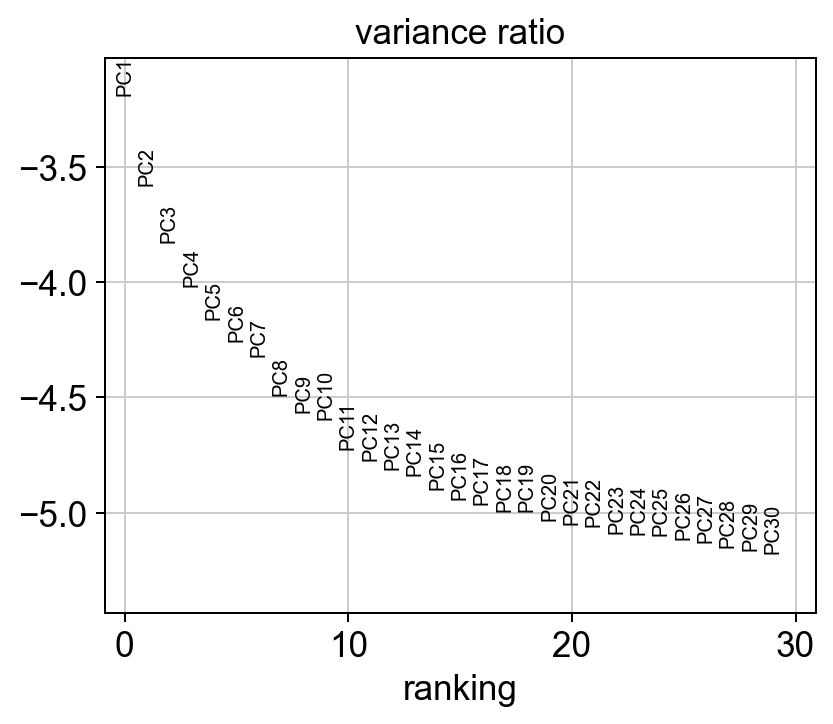

In [21]:
SUB_CLUSTERS = ["13"]       # наивные T (IL7R+, LEF1+, CCR7+): см. обоснование выше
print("Субкластеризуем:", SUB_CLUSTERS, [manual_annotations[c] for c in SUB_CLUSTERS])

hw_sub = hw[hw.obs[CLUSTER_KEY].isin(SUB_CLUSTERS)].copy()
hw_sub.X = hw_sub.layers["counts"].copy()
print(hw_sub)

sc.pp.highly_variable_genes(hw_sub, layer="counts", flavor="seurat_v3", n_top_genes=1500)
sc.pp.normalize_total(hw_sub, target_sum=1e4)
sc.pp.log1p(hw_sub)
sc.tl.pca(hw_sub, n_comps=30, mask_var="highly_variable", random_state=SEED)
sc.pl.pca_variance_ratio(hw_sub, n_pcs=30, log=True)

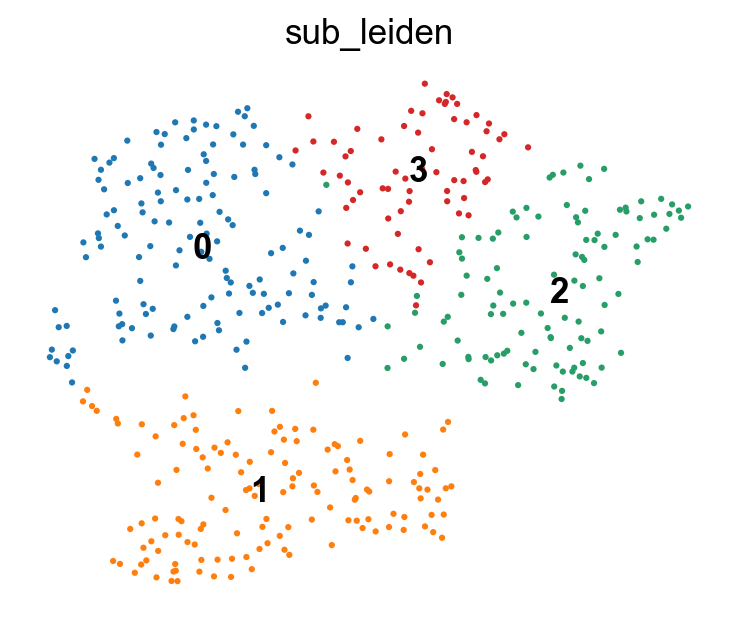

sub_leiden
0    140
1    135
2    110
3     69
Name: count, dtype: int64


,n_cells,top_markers
subcluster,,
0,140,"FOS, DUSP1, JUN, PPP1R15A, CD69, KLRB1, S100A11, FOSB"
1,135,"RPS26, RPS4Y1, ZNF331, FTH1, SRGN, HSPE1, YPEL5, SLC2A3"
2,110,"LEF1, RPS2, RPS4X, LDLRAP1, NOSIP, EEF1G, CHCHD10, MARCKSL1"
3,69,"CHI3L2, RPS4Y1, CUX1, ACTN1, ID2, EIF1AY, TOB1, CD27"


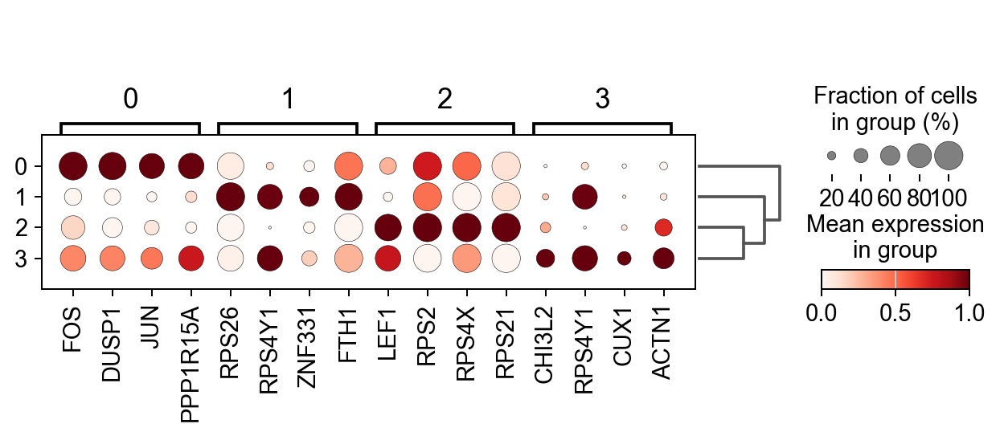

In [22]:
sc.pp.neighbors(hw_sub, n_neighbors=15, n_pcs=15, random_state=SEED)
sc.tl.umap(hw_sub, min_dist=0.3, random_state=SEED)
sc.tl.leiden(hw_sub, resolution=0.6, key_added="sub_leiden", random_state=SEED)
sc.pl.umap(hw_sub, color="sub_leiden", legend_loc="on data", size=25)
print(hw_sub.obs["sub_leiden"].value_counts().sort_index())

sc.tl.rank_genes_groups(hw_sub, groupby="sub_leiden", method="wilcoxon", reference="rest",
                        use_raw=False, tie_correct=True, pts=True, key_added="sub_wilcoxon")
sub_clusters = list(hw_sub.obs["sub_leiden"].cat.categories)
sub_markers = {}
for c in sub_clusters:
    df = sc.get.rank_genes_groups_df(hw_sub, group=c, key="sub_wilcoxon")
    df = df[(df["pvals_adj"] < 0.05) & (df["logfoldchanges"] > 0.5) & (df["pct_nz_group"] > 0.25)]
    sub_markers[c] = df.sort_values("scores", ascending=False)
display(pd.DataFrame({
    "subcluster": sub_clusters,
    "n_cells": [int((hw_sub.obs["sub_leiden"] == c).sum()) for c in sub_clusters],
    "top_markers": [", ".join(sub_markers[c]["names"].head(8)) for c in sub_clusters],
}).set_index("subcluster"))
sc.pl.rank_genes_groups_dotplot(hw_sub, key="sub_wilcoxon", groupby="sub_leiden", n_genes=4,
                                use_raw=False, standard_scale="var")

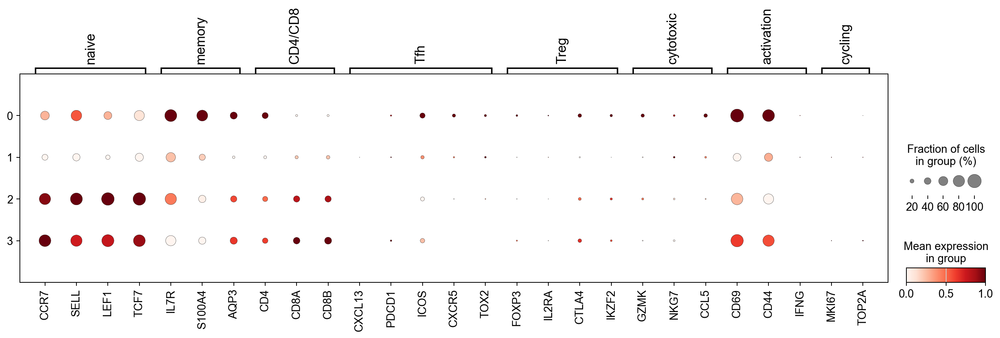

In [23]:
T_STATE_GENES = {
    "naive":      ["CCR7", "SELL", "LEF1", "TCF7"],
    "memory":     ["IL7R", "S100A4", "AQP3"],
    "CD4/CD8":    ["CD4", "CD8A", "CD8B"],
    "Tfh":        ["CXCL13", "PDCD1", "ICOS", "CXCR5", "TOX2"],
    "Treg":       ["FOXP3", "IL2RA", "CTLA4", "IKZF2"],
    "cytotoxic":  ["GZMK", "NKG7", "CCL5"],
    "activation": ["CD69", "CD44", "IFNG"],
    "cycling":    ["MKI67", "TOP2A"],
}
T_STATE_GENES = {k: [g for g in v if g in hw_sub.var_names] for k, v in T_STATE_GENES.items()}
sc.pl.dotplot(hw_sub, var_names={k: v for k, v in T_STATE_GENES.items() if v},
              groupby="sub_leiden", standard_scale="var", use_raw=False, figsize=(18, 4))

**Результаты** (454 клетки, 4 субкластера: 0 это 140 клеток, 1 это 135, 2 это 110, 3 это 69).

- **Субкластер 0:** `FOS`, `JUN`, `DUSP1`, `PPP1R15A`, `CD69`, также `IL7R`, `S100A4`, `CD44`; `CCR7`, `SELL`, `LEF1` низкие. Это активированные или памяти T-клетки, часть признаков может быть стрессом от обработки ткани.
- **Субкластер 1:** `RPS26`, `ZNF331`, `FTH1`, `SRGN`, `RPS4Y1`. Чётких маркеров типа нет, много рибосомных генов. Биологически не интерпретируется.
- **Субкластер 2:** `LEF1`, `RPS2`, `RPS4X`, `NOSIP`, высокие `CCR7`, `SELL`, `TCF7`. Наивные T (CD4 и CD8 не разделены).
- **Субкластер 3:** `CHI3L2`, `CUX1`, `ACTN1`, `CD27`, высокие `CCR7`, `LEF1`, `CD8A`, `CD8B`. Наивные CD8-подобные T.

**Разделить популяцию на интерпретируемые подгруппы удалось частично:** выделились активированные и памяти T (субкластер 0) и наивные (2 и 3), среди наивных видна CD8-подобная группа (3). Субкластер 1 не интерпретируется.

**Какие гены отличают субкластеры:** активация и память: `FOS`, `JUN`, `DUSP1`, `CD69`, `IL7R`, `S100A4`. Наивность: `CCR7`, `SELL`, `LEF1`, `TCF7`. CD8-подобные: `CD8A`, `CD8B`, `CD27`.

**Почему раньше этого не было видно:** при кластеризации всех клеток первые компоненты PCA описывают различия между B, T и миелоидными клетками, а различия внутри T-клеток слабее и теряются. После вырезания популяции и пересчёта HVG и PCA они становятся главными.

## Задание 7. Генные программы (gene scores)

Выбраны три программы:
- **цитотоксичность:** `NKG7`, `PRF1`, `GZMB`, `GNLY`, `GZMH`, `CTSW` (гены гранул NK и CD8 T, список с семинара и литература);
- **интерфероновый ответ:** `ISG15`, `IFIT1`, `IFIT3`, `MX1`, `IFI6`, `OAS1` (MSigDB Hallmark Interferon Alpha Response);
- **пролиферация:** `MKI67`, `TOP2A`, `PCNA`, `TYMS`, `STMN1`, `TUBA1B` (классические гены клеточного цикла; в герминальных центрах много делящихся B-клеток).

`score_genes` считает среднюю экспрессию набора минус средняя экспрессия случайных контрольных генов с похожим уровнем.

cytotoxic_score | использовано: 6 из 6 | нет в данных: []
interferon_score | использовано: 6 из 6 | нет в данных: []
proliferation_score | использовано: 6 из 6 | нет в данных: []


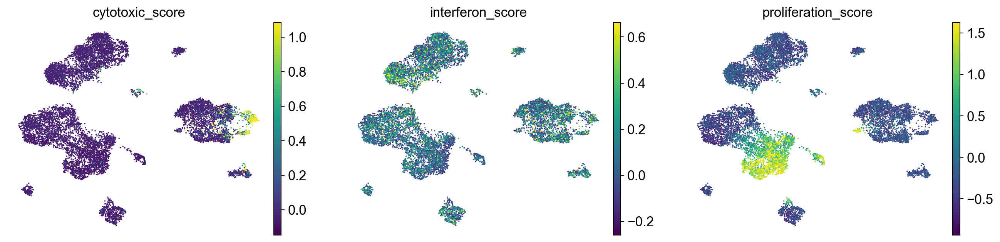

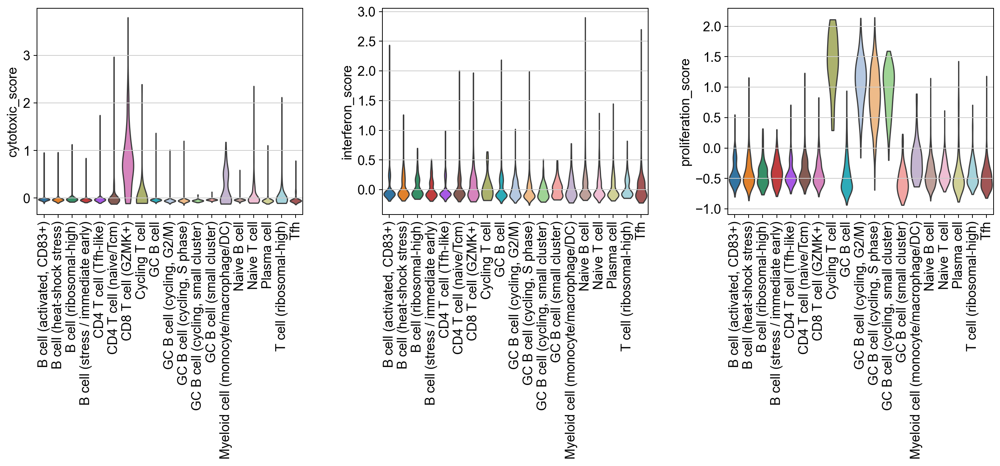

,cytotoxic_score,interferon_score,proliferation_score
manual_cell_type,,,
"B cell (activated, CD83+)",-0.027,0.006,-0.407
B cell (heat-shock stress),-0.025,0.054,-0.406
B cell (ribosomal-high),-0.017,0.040,-0.427
B cell (stress / immediate early),-0.037,0.008,-0.400
CD4 T cell (Tfh-like),-0.022,-0.004,-0.411
CD4 T cell (naive/Tcm),0.027,0.043,-0.378
CD8 T cell (GZMK+),0.785,0.077,-0.404
Cycling T cell,0.035,0.033,1.406
GC B cell,-0.040,0.023,-0.464


Популяция с максимумом по каждой программе:
cytotoxic_score        CD8 T cell (GZMK+)
interferon_score       CD8 T cell (GZMK+)
proliferation_score        Cycling T cell
dtype: category
Categories (19, object): ['B cell (activated, CD83+)', 'B cell (heat-shock stress)', 'B cell (ribosomal-high)', 'B cell (stress / immediate early)', ..., 'Naive T cell', 'Plasma cell', 'T cell (ribosomal-high)', 'Tfh']


,cytotoxic_score,interferon_score,proliferation_score
leiden_1.0,,,
0,-0.041,0.015,-0.470
1,-0.030,0.101,-0.370
2,-0.041,0.044,-0.462
3,-0.057,-0.039,0.882
4,-0.027,0.006,-0.407
5,0.027,0.043,-0.378
6,-0.022,-0.004,-0.411
7,-0.055,0.012,1.082
8,-0.045,-0.005,0.808


In [24]:
PROGRAMS = {
    "cytotoxic_score":     ["NKG7", "PRF1", "GZMB", "GNLY", "GZMH", "CTSW"],
    "interferon_score":    ["ISG15", "IFIT1", "IFIT3", "MX1", "IFI6", "OAS1"],
    "proliferation_score": ["MKI67", "TOP2A", "PCNA", "TYMS", "STMN1", "TUBA1B"],
}
for score, genes in PROGRAMS.items():
    present = [g for g in genes if g in hw.var_names]
    print(score, "| использовано:", len(present), "из", len(genes), "| нет в данных:", sorted(set(genes) - set(present)))
    sc.tl.score_genes(hw, gene_list=present, score_name=score, use_raw=False, random_state=SEED)

sc.pl.umap(hw, color=list(PROGRAMS), ncols=3, size=8, cmap="viridis", vmax="p99")
sc.pl.violin(hw, keys=list(PROGRAMS), groupby="manual_cell_type", rotation=90, stripplot=False, multi_panel=True)

summary = hw.obs.groupby("manual_cell_type", observed=True)[list(PROGRAMS)].mean().round(3)
display(summary)
print("Популяция с максимумом по каждой программе:")
print(summary.idxmax())

# то же по кластерам Leiden: так лучше видны малые группы
summary_cluster = hw.obs.groupby(CLUSTER_KEY, observed=True)[list(PROGRAMS)].mean().round(3)
display(summary_cluster)

**Где какая программа выражена сильнее всего** (по UMAP, violin plots и таблицам выше).

- **Цитотоксичность:** максимум у CD8 T (кластер 14, средний score 0,79), у остальных T-клеток и всех B-клеток около нуля. Небольшое повышение у миелоидного кластера 20 (0,21).
- **Пролиферация:** максимум у делящихся T (кластер 21, 1,41) и у делящихся B-клеток герминального центра (кластеры 3, 7, 8, 18, от 0,8 до 1,1). У остальных клеток значения ниже нуля.
- **Интерфероновый ответ:** слабый и популяцию не выделяет. Средние значения по кластерам от -0,04 до 0,10, чуть выше у CD8 T и части B-клеток. Для здорового донора без острой инфекции это ожидаемо. Отсутствие интерферонового ответа тоже результат.

**Как score помогают уточнить ручную аннотацию:**
1. Пролиферация делит GC B-клетки на покоящиеся (кластеры 0, 9, 19) и делящиеся (3, 7, 8, 18). Это состояние, а не тип, поэтому в названиях стоит `cycling`.
2. Кластер 21 автоматика назвала `Treg`. Высокая пролиферация при `CD3D` показала, что это делящиеся T-клетки.
3. Цитотоксичность отделяет CD8 T (кластер 14) от CD4 T-кластеров, которые иначе похожи по общим T-генам.
4. Предостережение: у миелоидного кластера 20 цитотоксический score выше фона, хотя это не цитотоксические клетки. Возможно, дело в `GZMB`, который выражают плазмацитоидные дендритные клетки, но это предположение. Score нужно читать вместе с маркерами типа.
5. Интерфероновая программа аннотацию не уточнила.

Высокий score показывает только повышенную экспрессию набора, но не то, что клетка выполняет эту функцию.

## Задание 8. Итоговые результаты и выводы

### 8.1. Итоговая визуализация

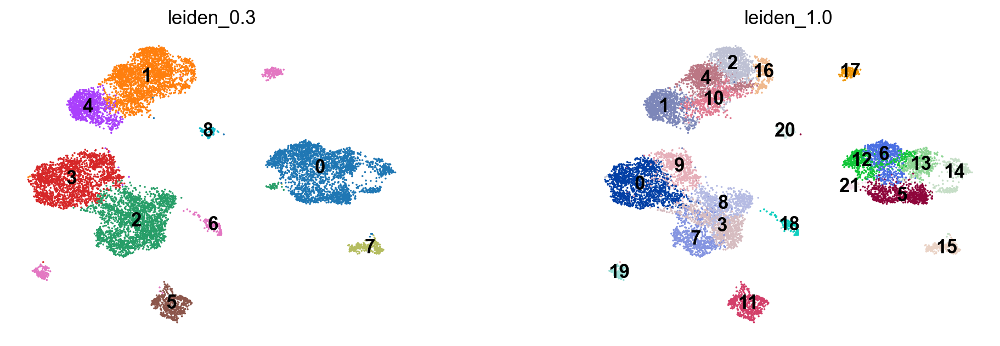

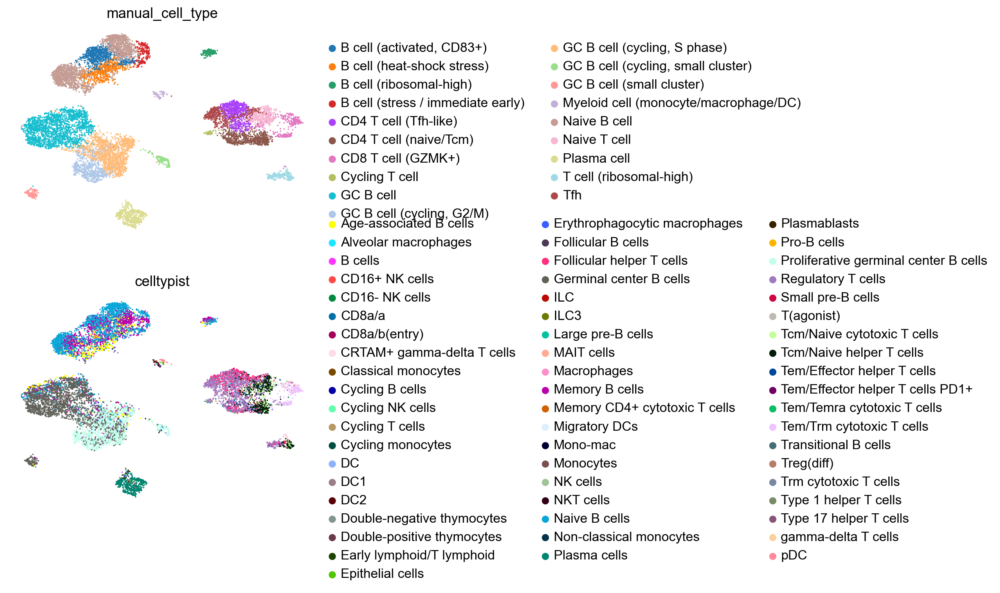

In [25]:
# 1. Две кластеризации
sc.pl.umap(hw, color=[f"leiden_{r}" for r in RESOLUTIONS], legend_loc="on data", size=8, ncols=2, wspace=0.3)
# 2-3. Ручная и автоматическая аннотации
sc.pl.umap(hw, color=["manual_cell_type", "celltypist"], size=8, ncols=1)

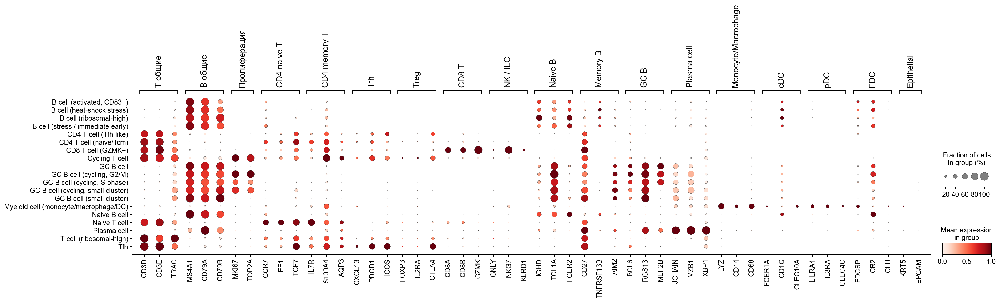

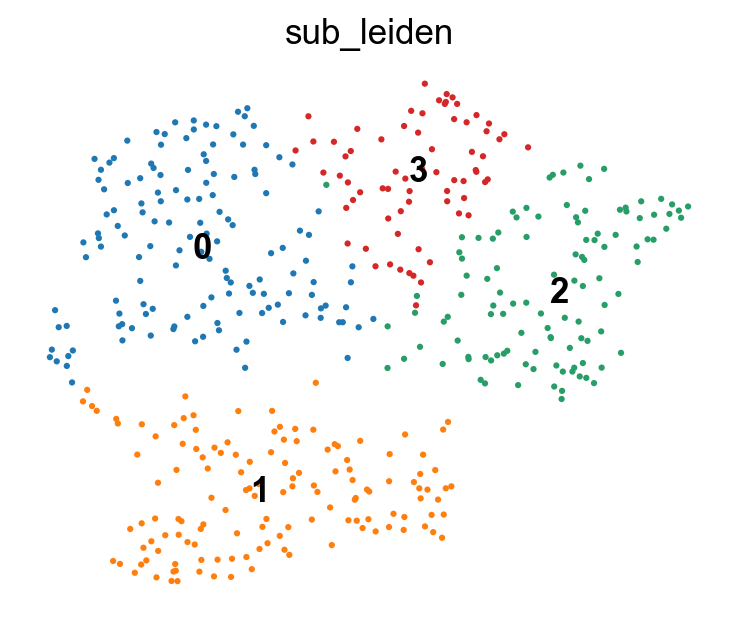

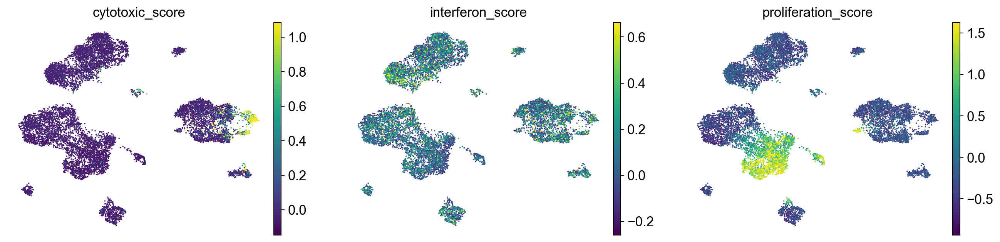

In [26]:
# 4. Dotplot основных маркеров по ручной аннотации
sc.pl.dotplot(hw, var_names={**GENERAL, **{k: v[:3] for k, v in PANELS.items()}},
              groupby="manual_cell_type", standard_scale="var", use_raw=False, figsize=(26, 5))
# 5. Субкластеры
sc.pl.umap(hw_sub, color="sub_leiden", legend_loc="on data", size=25)
# 6. Три программы
sc.pl.umap(hw, color=list(PROGRAMS), ncols=3, size=8, cmap="viridis", vmax="p99")

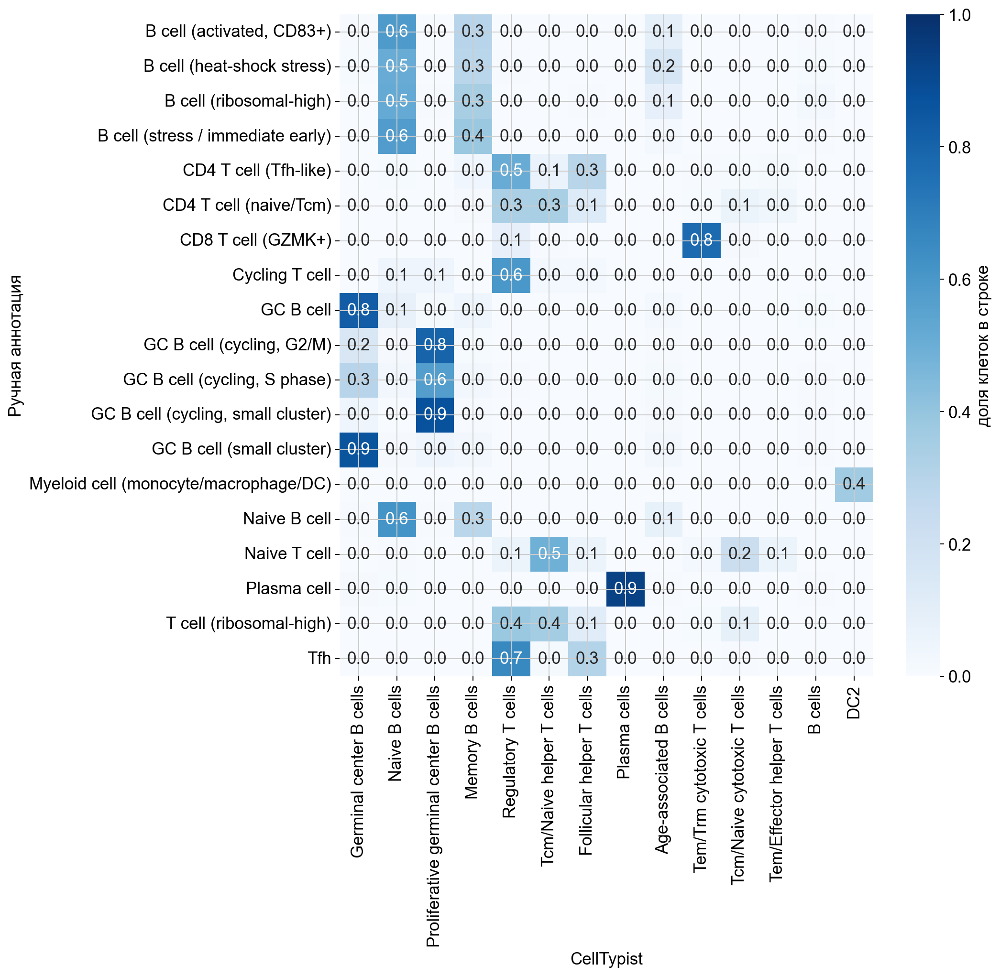

Клеток после QC: 11880 | генов: 17335
Кластеров Leiden: {'res=0.3': 9, 'res=1.0': 22}

Ручная аннотация (клеток):
manual_cell_type
GC B cell                                2137
Naive B cell                             1922
GC B cell (cycling, S phase)             1477
B cell (activated, CD83+)                 796
CD4 T cell (naive/Tcm)                    729
CD4 T cell (Tfh-like)                     684
GC B cell (cycling, G2/M)                 676
B cell (heat-shock stress)                548
Plasma cell                               537
Tfh                                       504
Naive T cell                              454
CD8 T cell (GZMK+)                        340
T cell (ribosomal-high)                   273
B cell (stress / immediate early)         220
B cell (ribosomal-high)                   156
GC B cell (cycling, small cluster)        150
GC B cell (small cluster)                 144
Myeloid cell (monocyte/macrophage/DC)      93
Cycling T cell                           

In [27]:
# 7. Сравнение ручной и автоматической аннотации (доля клеток каждой ручной метки по меткам CellTypist)
import seaborn as sns
share = pd.crosstab(hw.obs["manual_cell_type"], hw.obs["celltypist"], normalize="index")
share = share[hw.obs["celltypist"].value_counts().index[:14]]

plt.figure(figsize=(12, 0.45 * len(share) + 3))
sns.heatmap(share, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".1f", cbar_kws={"label": "доля клеток в строке"})
plt.xlabel("CellTypist"); plt.ylabel("Ручная аннотация")
plt.tight_layout(); plt.show()

print("Клеток после QC:", hw.n_obs, "| генов:", hw.n_vars)
print("Кластеров Leiden:", {f"res={r}": hw.obs[f'leiden_{r}'].nunique() for r in RESOLUTIONS})
print("\nРучная аннотация (клеток):\n" + hw.obs["manual_cell_type"].value_counts().to_string())
print("\nСубкластеры (клеток):\n" + hw_sub.obs["sub_leiden"].value_counts().sort_index().to_string())

### 8.2. Заключение

**1. Основные клеточные популяции.**
После QC осталось 11 880 клеток из 12 000. Они собраны в 22 кластера (resolution 1.0) и пять групп: B-клетки герминального центра (4 584, 38,6 %, включая делящиеся), покоящиеся, наивные и активированные B-клетки (3 642, 30,7 %), T-клетки (3 024, 25,5 %: CD4 наивные и Tfh, CD8, делящиеся), плазматические клетки (537, 4,5 %) и миелоидные клетки (93, 0,8 %). Отдельных NK и ILC нет. Часть кластеров это состояния или артефакты, а не типы: делящиеся GC B, стресс от обработки ткани (кластеры 10 и 16).

**2. Маркерные гены.**
Какие гены определяют популяции по результатам обработки -  GC B: `MEF2B`, `RGS13`, `SERPINA9`, `LMO2`, `BCL6`. Делящиеся: `MKI67`, `TOP2A`, `PLK1`, `TYMS`. Покоящиеся и наивные B: `MS4A1`, `BANK1`, `FCER2`, `TCL1A`, `IGHD`. Плазматические: `XBP1`, `PRDM1`, `JCHAIN`, `MZB1`. T-клетки: `CD3D`, `CD3E`, `IL7R`, `CCR7`, `LEF1`. Tfh: `PDCD1`, `ICOS`, `CXCR5`, `CXCL13`, `TOX2`. CD8 T: `CD8A`, `CD8B`, `GZMK`, `EOMES`, `CCL5`. Миелоидные: `LYZ`, `CST3`, `TYROBP`, `CD14`. Подробности в таблице аннотации (задание 4).

**3. Ручная и автоматическая аннотации.**
Аннотации согласуются для чётких групп: плазматические клетки, GC B и делящиеся GC B (даже по состоянию), CD8 T, миелоидные клетки. Расходятся для CD4 T (CellTypist относит большую часть Tfh-кластеров к Treg, но `FOXP3` и `IL2RA` в них нет, а авторы датасета тоже называют их Tfh), в делении B-клеток на naive, memory и age-associated и для кластеров-артефактов, которые CellTypist не видит. Лучше всего работает сочетание: CellTypist как гипотеза, маркеры как проверка.

**4. Субкластеризация.**
Кластер наивных T-клеток (454 клетки) разделился на 4 субкластера: активированные или памяти T (`FOS`, `JUN`, `CD69`, `IL7R`, `S100A4`), две группы наивных T с `CCR7`, `SELL`, `LEF1` (одна CD8-подобная: `CD8A`, `CD8B`, `CD27`) и группу, которую биологически объяснить не удалось. В двух субкластерах есть гены Y-хромосомы, то есть часть деления идёт по полу донора.

**5. Генные программы.**
Пролиферация разделила GC B-клетки на покоящиеся и делящиеся и исправила название кластера 21 (делящиеся T-клетки, а не Treg). Цитотоксичность отделила CD8 T от CD4 T. Интерфероновый ответ популяцию не выделил, для здорового донора это ожидаемо. Ограничение: у миелоидного кластера цитотоксический score повышен, хотя клетки не цитотоксические, поэтому score читаем вместе с маркерами.

**Ограничения работы.** Использована подвыборка 12 000 из 32 607 клеток. В наборе нет митохондриальных генов, поэтому фильтрация по ним невозможна. Кластеры 15, 17, 18 и 19 малые, их подтипы оценивать трудно.